# DS-471 Machine Learning Project — Credit Card Default Prediction

- **Topic:** Credit Card Default Prediction
- **Dataset:** [UCI Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) (Yeh, 2009) — 30,000 credit-card clients of a bank in Taiwan, 23 features
- **Task:** binary classification — predict whether a client will **default** on the next monthly payment (October 2005), using six months of billing and repayment history (April–September 2005) and basic personal information.

| Group member | Student ID |
|---|---|
| Thamer Bander Almutairi | S230006300 |
| Abdullah Mutlaq Albugami | S220014331 |
| Khalid Alhamalawi | S220016917 |
| Khalid Alqarni | S220022107 |

- **CRN:** 10700
- **GitHub repository:** https://github.com/Alhelfi1/DS471-Credit-Card-Default-Prediction

### Contents
0. Setup
1. **Stage 1** — Data cleaning, preparation and exploration
2. **Stage 2** — Data splitting
3. **Stage 3** — Model selection and development
4. **Stage 4** — Model training and hyperparameter optimisation (incl. neural-network training/validation curves)
5. **Stage 5** — Final evaluation and comparison
6. Discussion and conclusion

**How to run.** Run all cells from top to bottom in Google Colab or Jupyter (about 25 minutes on a normal 2-core CPU; the grid search takes about 12 minutes). The notebook reads `data/default_of_credit_card_clients.csv` from the repository. If that file is missing (for example in a fresh Colab session), the first data cell downloads the original file from the UCI repository automatically. Only standard libraries are used (numpy, pandas, scipy, scikit-learn, matplotlib, seaborn — all pre-installed in Colab). Every figure is saved to `figures/` and every results table to `results/`. One random seed (`RANDOM_STATE = 42`) makes all results reproducible.

## 0. Setup

In [1]:
import os, io, sys, time, copy, json, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
import scipy
import sklearn

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, cross_validate,
                                     validation_curve, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
                             log_loss, brier_score_loss)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

RANDOM_STATE = 42          # one seed for every random step -> reproducible results
np.random.seed(RANDOM_STATE)
for folder in ['data', 'figures', 'results']:
    os.makedirs(folder, exist_ok=True)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"scipy {scipy.__version__} | matplotlib {mpl.__version__} | seaborn {sns.__version__}")

numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | seaborn 0.13.2


In [2]:
# Plot style: recessive grid, thin marks and a colour-blind-safe categorical palette
INK, INK2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
C_NO, C_YES = '#2a78d6', '#eb6834'          # no default / default
C_TRAIN, C_VAL = '#2a78d6', '#eb6834'       # training / validation curves
MODEL_ORDER = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Neural Network']
MODEL_COLORS = {'Logistic Regression': '#2a78d6', 'Decision Tree': '#e87ba4', 'Random Forest': '#eda100',
                'Gradient Boosting': '#1baf7a', 'Neural Network': '#eb6834'}
SHORT = {'Logistic Regression': 'LR', 'Decision Tree': 'DT', 'Random Forest': 'RF',
         'Gradient Boosting': 'GB', 'Neural Network': 'NN'}
BLUES = LinearSegmentedColormap.from_list('blues', ['#f4f8fd', '#9ec5f4', '#2a78d6', '#0d366b'])
DIVERGING = LinearSegmentedColormap.from_list(
    'diverging', ['#0d366b', '#2a78d6', '#9ec5f4', '#f0efec', '#f2a7a6', '#e34948', '#8f1f1f'])

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'font.size': 10, 'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
    'axes.titlelocation': 'left', 'axes.labelsize': 10, 'axes.labelcolor': INK2,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'grid.linestyle': '-', 'axes.axisbelow': True,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'lines.linewidth': 2,
    'lines.solid_capstyle': 'round', 'lines.solid_joinstyle': 'round',
    'legend.frameon': False, 'legend.fontsize': 9, 'legend.labelcolor': INK2,
    'figure.titlesize': 12, 'figure.titleweight': 'bold', 'figure.figsize': (8, 4.2),
})

def save_fig(fig, name):
    # high-resolution copy for the report; the notebook shows the inline version
    fig.savefig(f'figures/{name}.png', dpi=200, bbox_inches='tight', facecolor='white')

def pct_axis(ax, axis='y'):
    fmt = mpl.ticker.PercentFormatter(1.0, decimals=0)
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(fmt)

---
## Stage 1 — Data Cleaning, Preparation and Exploration

**Data-leakage policy.** The checks and plots in this stage use all clients because they do not fit anything that is later used for prediction. Every step that *learns* from data — scalers, transformers, models, hyperparameters and decision thresholds — is fitted on the **training data only** (Stages 2–4), inside scikit-learn `Pipeline`s.

### 1.1 Loading and understanding the dataset
Each row is one credit-card client. The bank recorded the credit limit, personal information, and — for each month from **April to September 2005** — the repayment status, the bill amount and the amount paid. The target says whether the client **defaulted on the payment due in October 2005**.

*Data source.* `data/default_of_credit_card_clients.csv` is an exact CSV copy of the original UCI file `default of credit card clients.xls` (same 30,000 rows and values; only the generic first header row "X1 … X23, Y" was dropped).

In [3]:
DATA_PATH = 'data/default_of_credit_card_clients.csv'
UCI_URL = 'https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip'

if not os.path.exists(DATA_PATH):
    # Fallback for a fresh Colab session without the repository's data folder:
    # download the original file from the UCI repository once and store it as CSV.
    import zipfile, urllib.request, subprocess
    try:
        import xlrd  # noqa: F401  (pandas needs it to read the original .xls file)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'xlrd'], check=True)
    with urllib.request.urlopen(UCI_URL) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    xls_name = [n for n in archive.namelist() if n.lower().endswith('.xls')][0]
    pd.read_excel(io.BytesIO(archive.read(xls_name)), header=1).to_csv(DATA_PATH, index=False)

raw = pd.read_csv(DATA_PATH)
print('Shape (rows, columns):', raw.shape)
raw.head()

Shape (rows, columns): (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
variables = pd.DataFrame([
    ('ID', 'Client identifier', 'integer'),
    ('LIMIT_BAL', 'Amount of credit given, incl. family (supplementary) credit, NT$', 'numeric'),
    ('SEX', 'Gender: 1 = male, 2 = female', 'categorical (binary)'),
    ('EDUCATION', '1 = graduate school, 2 = university, 3 = high school, 4 = others', 'categorical'),
    ('MARRIAGE', 'Marital status: 1 = married, 2 = single, 3 = others', 'categorical'),
    ('AGE', 'Age in years', 'numeric'),
    ('PAY_0, PAY_2 ... PAY_6', 'Repayment status Sep 2005 (PAY_0) back to Apr 2005 (PAY_6): -1 = paid duly, 1-9 = payment delay in months', 'ordinal'),
    ('BILL_AMT1 ... BILL_AMT6', 'Bill statement amount Sep 2005 (1) back to Apr 2005 (6), NT$', 'numeric'),
    ('PAY_AMT1 ... PAY_AMT6', 'Amount paid in Sep 2005 (1) back to Apr 2005 (6), NT$', 'numeric'),
    ('default payment next month', 'TARGET: 1 = client defaulted in Oct 2005, 0 = no default', 'binary'),
], columns=['Column(s)', 'Description (UCI documentation)', 'Type'])
variables

,Column(s),Description (UCI documentation),Type
0,ID,Client identifier,integer
1,LIMIT_BAL,"Amount of credit given, incl. family (suppleme...",numeric
2,SEX,"Gender: 1 = male, 2 = female",categorical (binary)
3,EDUCATION,"1 = graduate school, 2 = university, 3 = high ...",categorical
4,MARRIAGE,"Marital status: 1 = married, 2 = single, 3 = o...",categorical
5,AGE,Age in years,numeric
6,"PAY_0, PAY_2 ... PAY_6",Repayment status Sep 2005 (PAY_0) back to Apr ...,ordinal
7,BILL_AMT1 ... BILL_AMT6,Bill statement amount Sep 2005 (1) back to Apr...,numeric
8,PAY_AMT1 ... PAY_AMT6,Amount paid in Sep 2005 (1) back to Apr 2005 (...,numeric
9,default payment next month,"TARGET: 1 = client defaulted in Oct 2005, 0 = ...",binary


In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [6]:
raw.drop(columns='ID').describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_0,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_5,30000.0,-0.3,1.1,-2.0,-1.0,0.0,0.0,8.0


**Data types and scales.** All 25 columns are integers. `SEX`, `EDUCATION` and `MARRIAGE` are categorical codes, the six `PAY_*` columns are ordinal status codes, and the 13 monetary columns are in New Taiwan dollars. The scales differ enormously: `AGE` runs from 21 to 79, while bills reach NT$1.66 million, payments NT$1.68 million and some bills are **negative**. The monetary columns are strongly right-skewed (the mean is far above the median), so scaling and transformation will matter for the distance- and gradient-based models.

The repayment-status columns are called `PAY_0, PAY_2, …, PAY_6` in the original file (there is no `PAY_1`), which is inconsistent with `BILL_AMT1 … 6` and `PAY_AMT1 … 6`. They are renamed `PAY_1 … PAY_6` (1 = September … 6 = April), and the target is renamed `DEFAULT`.

In [7]:
# Consistent names: the six repayment-status columns become PAY_1 ... PAY_6 (UCI skips PAY_1),
# matching BILL_AMT1 ... BILL_AMT6 and PAY_AMT1 ... PAY_AMT6 (1 = September 2005, 6 = April 2005).
df = raw.rename(columns={'PAY_0': 'PAY_1', 'default payment next month': 'DEFAULT'})
PAY_COLS = [f'PAY_{k}' for k in range(1, 7)]
BILL_COLS = [f'BILL_AMT{k}' for k in range(1, 7)]
PAYAMT_COLS = [f'PAY_AMT{k}' for k in range(1, 7)]
MONTHS = ['Sep', 'Aug', 'Jul', 'Jun', 'May', 'Apr']
assert df['ID'].is_unique
print('Columns:', list(df.columns))

Columns: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT']


### 1.2 Target variable

            count  percent
DEFAULT                   
No default  23364     77.9
Default      6636     22.1

Imbalance ratio (no default : default) = 3.52 : 1
Accuracy of a model that always predicts 'no default' = 77.9%


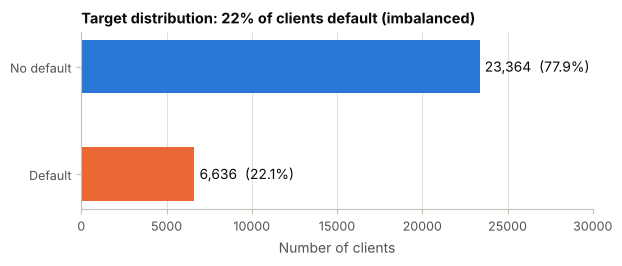

In [8]:
labels = df['DEFAULT'].map({0: 'No default', 1: 'Default'})
target_summary = pd.DataFrame({'count': labels.value_counts(),
                               'percent': (labels.value_counts(normalize=True) * 100).round(1)})
print(target_summary)
ratio = target_summary.loc['No default', 'count'] / target_summary.loc['Default', 'count']
print(f'\nImbalance ratio (no default : default) = {ratio:.2f} : 1')
print(f"Accuracy of a model that always predicts 'no default' = {target_summary.loc['No default', 'percent']}%")

fig, ax = plt.subplots(figsize=(6.6, 2.3))
order = ['No default', 'Default']
bars = ax.barh(order, target_summary.loc[order, 'count'], color=[C_NO, C_YES], height=0.5)
for bar, c in zip(bars, order):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height() / 2,
            f"{target_summary.loc[c, 'count']:,}  ({target_summary.loc[c, 'percent']}%)", va='center', color=INK)
ax.set_xlim(0, 30000)
ax.set_xlabel('Number of clients')
ax.grid(axis='y', visible=False)
ax.invert_yaxis()
ax.set_title('Target distribution: 22% of clients default (imbalanced)')
save_fig(fig, 'fig01_target_distribution')
plt.show()

**Finding.** 6,636 of 30,000 clients (22.1%) defaulted — an **imbalanced** problem (3.52 non-defaulters per defaulter). A model that always predicts "no default" is 77.9% accurate but useless.

**Decisions.**
* **Metrics:** accuracy alone is misleading, so we use ROC-AUC, PR-AUC (average precision), recall, precision and F1 for the default class (Stage 5).
* **Stratified splits**, so that every subset keeps the 22% default rate (Stage 2).
* **No synthetic over-sampling (SMOTE).** Instead we use (1) `class_weight='balanced'` as a tunable hyperparameter, kept only when cross-validation prefers it, and (2) a **decision threshold tuned on the validation set**. Threshold tuning changes the decisions without inventing artificial clients.

**Target encoding.** The target is already coded **1 = default** (positive class) and **0 = no default**, so precision, recall and F1 directly measure how well defaulters are detected.

### 1.3 Missing values

In [9]:
print('Missing values in the whole table:', int(df.isna().sum().sum()))
# Undocumented codes are a hidden form of missing information -> checked in the "inconsistent data" step
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f'{col:<10} codes:', df[col].value_counts().sort_index().to_dict())

Missing values in the whole table: 0
SEX        codes: {1: 11888, 2: 18112}
EDUCATION  codes: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE   codes: {0: 54, 1: 13659, 2: 15964, 3: 323}


There are **no missing (NaN) values**. However, `EDUCATION` and `MARRIAGE` contain **codes that the documentation does not define** (0, 5, 6 and 0). These are a hidden form of missing or unknown information and are handled in 1.5.

### 1.4 Duplicates

In [10]:
features_and_target = [c for c in df.columns if c != 'ID']
feature_cols_raw = [c for c in features_and_target if c != 'DEFAULT']
dup_exact = df.duplicated(subset=features_and_target)            # identical in all 23 features AND the target
dup_features = df.duplicated(subset=feature_cols_raw)            # identical in all 23 features
in_dup_group = df.duplicated(subset=features_and_target, keep=False)
conflicting = (df.groupby(feature_cols_raw)['DEFAULT'].nunique() > 1).sum()

print('Duplicate IDs                                  :', int(df['ID'].duplicated().sum()))
print('Rows that repeat another row (features+target) :', int(dup_exact.sum()))
print('Rows that repeat another feature vector        :', int(dup_features.sum()))
print('Groups with identical features but different targets:', int(conflicting))
inactive = (df.loc[in_dup_group, BILL_COLS] == 0).all(axis=1).mean()
print(f'Share of duplicated rows with all six bills = 0 (inactive accounts): {inactive:.0%}')
df.loc[in_dup_group].sort_values(feature_cols_raw).head(6)[['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
                                                            'PAY_1', 'BILL_AMT1', 'PAY_AMT1', 'DEFAULT']]

Duplicate IDs                                  : 0
Rows that repeat another row (features+target) : 35
Rows that repeat another feature vector        : 56
Groups with identical features but different targets: 21
Share of duplicated rows with all six bills = 0 (inactive accounts): 86%


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,BILL_AMT1,PAY_AMT1,DEFAULT
12430,12431,20000,1,2,2,24,2,1650,0,1
14294,14295,20000,1,2,2,24,2,1650,0,1
1759,1760,50000,1,2,2,26,1,0,0,0
10250,10251,50000,1,2,2,26,1,0,0,0
7170,7171,50000,2,1,2,23,1,0,0,0
17032,17033,50000,2,1,2,23,1,0,0,0


**Findings.**
* Every `ID` is unique.
* **35 rows** repeat another row exactly in all 23 features *and* the target.
* 86% of those duplicated rows are inactive accounts with zero bills in all six months.
* 21 groups of clients have identical features but **different** targets.

**Decisions.**
* **Remove the 35 exact duplicates.** An identical copy adds no information. If one copy fell into the training set and the other into the test set, the test result would be slightly optimistic. Removing them costs only 0.12% of the data.
* **Keep the 21 conflicting groups.** Different outcomes prove these are different clients. Identical inputs with different outcomes are genuine noise that no model can remove.
* **Drop `ID`.** It is an identifier with no predictive meaning.

In [11]:
n_before = len(df)
df = df.loc[~dup_exact].drop(columns='ID').reset_index(drop=True)
print(f'Removed {n_before - len(df)} exact duplicate rows -> {len(df):,} clients remain '
      f'({(n_before - len(df)) / n_before:.2%} of the data)')
print('Default rate after removal:', f"{df['DEFAULT'].mean():.2%}")

Removed 35 exact duplicate rows -> 29,965 clients remain (0.12% of the data)
Default rate after removal: 22.13%


### 1.5 Inconsistent data
**(a) Undocumented category codes.**

In [12]:
edu_names = {1: 'graduate school', 2: 'university', 3: 'high school', 4: 'others', 0: 'undocumented (0)',
             5: 'undocumented (5)', 6: 'undocumented (6)'}
mar_names = {1: 'married', 2: 'single', 3: 'others', 0: 'undocumented (0)'}
code_table = pd.concat([
    df.groupby('EDUCATION')['DEFAULT'].agg(clients='count', default_rate='mean')
      .rename(index=lambda c: f'EDUCATION = {c}: {edu_names[c]}'),
    df.groupby('MARRIAGE')['DEFAULT'].agg(clients='count', default_rate='mean')
      .rename(index=lambda c: f'MARRIAGE = {c}: {mar_names[c]}'),
])
code_table['default_rate'] = (code_table['default_rate'] * 100).round(1)
code_table

,clients,default_rate
EDUCATION = 0: undocumented (0),14,0.0
EDUCATION = 1: graduate school,10563,19.2
EDUCATION = 2: university,14019,23.7
EDUCATION = 3: high school,4915,25.2
EDUCATION = 4: others,123,5.7
EDUCATION = 5: undocumented (5),280,6.4
EDUCATION = 6: undocumented (6),51,15.7
MARRIAGE = 0: undocumented (0),54,9.3
MARRIAGE = 1: married,13643,23.5
MARRIAGE = 2: single,15945,20.9


`EDUCATION` codes 0, 5 and 6 (345 clients) and `MARRIAGE` code 0 (54 clients) are not defined in the documentation. For `EDUCATION`, their default rates (0–16%) are low, like the documented "others" group (5.7%). `MARRIAGE` = 0 (9.3%) is lower than "others" (26.0%), but 54 clients are too few for a separate group.

**Decision: merge them into the documented "others" category** (`EDUCATION = 4`, `MARRIAGE = 3`).
* Dropping these 399 clients would lose data.
* Keeping them as separate categories would create groups too small to estimate reliably.
* "Others" is the documented catch-all.

In [13]:
# Undocumented codes are merged into the documented "others" category
edu_fix = df['EDUCATION'].isin([0, 5, 6])
mar_fix = df['MARRIAGE'].eq(0)
df.loc[edu_fix, 'EDUCATION'] = 4
df.loc[mar_fix, 'MARRIAGE'] = 3
print(f'EDUCATION: {int(edu_fix.sum())} clients with codes 0/5/6 -> 4 (others)')
print(f'MARRIAGE : {int(mar_fix.sum())} clients with code 0 -> 3 (others)')
print('EDUCATION codes now:', df['EDUCATION'].value_counts().sort_index().to_dict())
print('MARRIAGE codes now :', df['MARRIAGE'].value_counts().sort_index().to_dict())

EDUCATION: 345 clients with codes 0/5/6 -> 4 (others)
MARRIAGE : 54 clients with code 0 -> 3 (others)
EDUCATION codes now: {1: 10563, 2: 14019, 3: 4915, 4: 468}
MARRIAGE codes now : {1: 13643, 2: 15945, 3: 377}


**(b) Repayment-status codes.**

In [14]:
pay_counts = pd.DataFrame({col: df[col].value_counts() for col in PAY_COLS}).fillna(0).astype(int).sort_index()
pay_counts.index.name = 'status code'
print('Repayment-status codes per month (PAY_1 = Sep ... PAY_6 = Apr):')
display(pay_counts)

# Evidence for the meaning of the undocumented codes -2 and 0:
# share of clients whose bill in the same month is zero or negative (nothing to pay)
evidence = pd.DataFrame({
    f'{p} ({m})': [(df.loc[df[p] == s, b] <= 0).mean() * 100 for s in [-2, -1, 0]]
    for p, b, m in zip(PAY_COLS, BILL_COLS, MONTHS)}, index=['status -2', 'status -1', 'status 0']).round(1)
print('% of clients with a bill <= 0 in the same month, by status code:')
evidence

Repayment-status codes per month (PAY_1 = Sep ... PAY_6 = Apr):


,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
status code,,,,,,
-2,2750,3752,4055,4318,4516,4865
-1,5682,6046,5934,5683,5535,5736
0,14737,15730,15764,16455,16947,16286
1,3667,28,4,2,0,0
2,2666,3926,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,75,68,83,48
5,26,25,21,35,17,13
6,11,12,23,5,4,19


% of clients with a bill <= 0 in the same month, by status code:


,PAY_1 (Sep),PAY_2 (Aug),PAY_3 (Jul),PAY_4 (Jun),PAY_5 (May),PAY_6 (Apr)
status -2,32.5,55.3,61.2,66.5,68.0,70.6
status -1,0.1,11.6,9.5,10.2,10.8,10.4
status 0,0.0,1.8,2.0,1.8,2.4,3.8


**Findings.**
* The documentation defines only −1 ("paid duly") and 1–9 (months of delay), but the data also contain **−2 and 0**. These are frequent: 0 is the most common value.
* The second table shows what the codes mean in practice. With status −2, 33–71% of clients have a bill ≤ 0 in the same month, compared with 0–12% for −1 and 0–4% for 0.
* This supports the interpretation commonly used for this dataset:
  * **−2 = no credit used** (nothing to pay);
  * **−1 = paid in full**;
  * **0 = revolving credit** (minimum payment made, balance carried over).
* A one-month delay (code 1) occurs 3,667 times in September but almost never in the other months (28, 4, 2, 0, 0). The source evidently coded the months differently. This cannot be corrected without the bank's documentation.

**Decision.**
* Keep the codes as ordinal values (≤ 0 = no delay, k = k months of delay).
* Add **status indicators** for the most recent month (1.8). The codes −2, −1 and 0 are not ordered by risk, as Figure 5a shows.

**(c) Other consistency checks.**

In [15]:
checks = pd.Series({
    'clients with at least one negative bill (credit balance)': int((df[BILL_COLS] < 0).any(axis=1).sum()),
    'clients with a bill above their credit limit (at least once)': int(df[BILL_COLS].gt(df['LIMIT_BAL'], axis=0).any(axis=1).sum()),
    'negative payment amounts': int((df[PAYAMT_COLS] < 0).sum().sum()),
    'negative or zero credit limits': int((df['LIMIT_BAL'] <= 0).sum()),
    'AGE minimum': int(df['AGE'].min()), 'AGE maximum': int(df['AGE'].max()),
    'LIMIT_BAL minimum (NT$)': int(df['LIMIT_BAL'].min()), 'LIMIT_BAL maximum (NT$)': int(df['LIMIT_BAL'].max()),
})
checks.to_frame('value')

,value
clients with at least one negative bill (credit balance),1930
clients with a bill above their credit limit (at least once),3931
negative payment amounts,0
negative or zero credit limits,0
AGE minimum,21
AGE maximum,79
LIMIT_BAL minimum (NT$),10000
LIMIT_BAL maximum (NT$),1000000


* **Negative bills (1,930 clients)** are credit balances, e.g. after an overpayment or a refund. They are valid and are kept; the transformation in 1.7 preserves their sign.
* **Bills above the credit limit (3,931 clients)** are possible through interest, fees or tolerated over-limit spending. They are kept.
* There are no negative payments or limits, and ages (21–79) and limits (NT$10,000–1,000,000) are plausible.

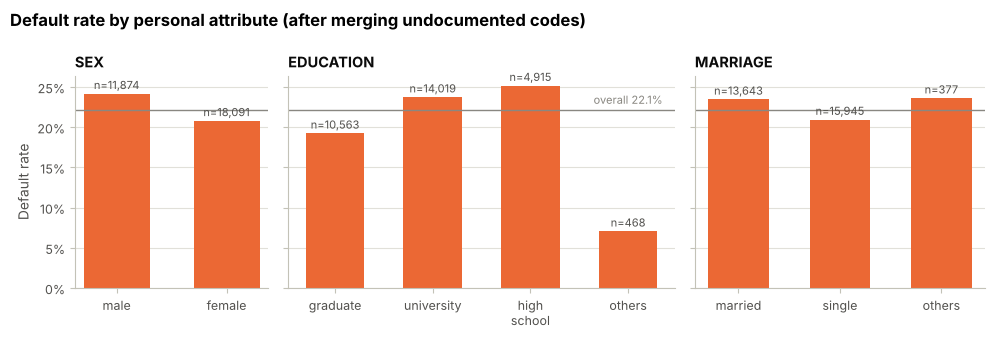

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True, gridspec_kw={'width_ratios': [2, 4, 3]})
base_rate = df['DEFAULT'].mean()
panels = [('SEX', {1: 'male', 2: 'female'}), ('EDUCATION', {1: 'graduate', 2: 'university', 3: 'high\nschool', 4: 'others'}),
          ('MARRIAGE', {1: 'married', 2: 'single', 3: 'others'})]
for ax, (col, names) in zip(axes, panels):
    g = df.groupby(col)['DEFAULT'].agg(['count', 'mean'])
    bars = ax.bar([names[i] for i in g.index], g['mean'], color=C_YES, width=0.6)
    for bar, n in zip(bars, g['count']):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.006, f'n={n:,}', ha='center', fontsize=8, color=INK2)
    ax.axhline(base_rate, color=MUTED, linewidth=1)
    ax.set_title(col)
    ax.grid(axis='x', visible=False)
    pct_axis(ax)
axes[0].set_ylabel('Default rate')
axes[1].text(3, base_rate + 0.008, f'overall {base_rate:.1%}', ha='center', fontsize=8, color=MUTED)
fig.suptitle('Default rate by personal attribute (after merging undocumented codes)', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig02_default_rate_by_category')
plt.show()

The personal attributes are only weakly related to default. Default rates are:
* by sex: 24.2% for men vs 20.8% for women;
* by education: 19.2% (graduate school) to 25.2% (high school);
* by marital status: 23.5% married vs about 21% single.

### 1.6 Outliers

In [17]:
MONEY_COLS = ['LIMIT_BAL'] + BILL_COLS + PAYAMT_COLS
q1, q3 = df[MONEY_COLS + ['AGE']].quantile(0.25), df[MONEY_COLS + ['AGE']].quantile(0.75)
iqr = q3 - q1
is_outlier = (df[MONEY_COLS + ['AGE']] < q1 - 1.5 * iqr) | (df[MONEY_COLS + ['AGE']] > q3 + 1.5 * iqr)
outlier_rows = is_outlier.any(axis=1)
print(f'1.5 x IQR rule on the 13 monetary columns + AGE: {int(is_outlier.values.sum()):,} outlying values; '
      f'{int(outlier_rows.sum()):,} clients ({outlier_rows.mean():.1%}) have at least one')
print(f"Default rate among those clients: {df.loc[outlier_rows, 'DEFAULT'].mean():.1%} "
      f"(vs {df['DEFAULT'].mean():.1%} overall)")
outlier_table = pd.DataFrame({
    'IQR outliers': is_outlier.sum(), '% of clients': (is_outlier.mean() * 100).round(1),
    'upper fence': (q3 + 1.5 * iqr).round(0), 'maximum': df[MONEY_COLS + ['AGE']].max(),
    'default rate of outliers (%)': [round(df.loc[is_outlier[c], 'DEFAULT'].mean() * 100, 1) for c in is_outlier.columns],
}).sort_values('IQR outliers', ascending=False)
outlier_table

1.5 x IQR rule on the 13 monetary columns + AGE: 32,670 outlying values; 10,452 clients (34.9%) have at least one
Default rate among those clients: 15.2% (vs 22.1% overall)


,IQR outliers,% of clients,upper fence,maximum,default rate of outliers (%)
PAY_AMT4,2993,10.0,9590.0,621000,13.5
PAY_AMT6,2960,9.9,9804.0,528666,12.4
PAY_AMT5,2944,9.8,9714.0,426529,12.7
PAY_AMT1,2742,9.2,11020.0,873552,12.3
BILL_AMT5,2724,9.1,122937.0,927171,20.6
PAY_AMT2,2723,9.1,11225.0,1684259,10.4
BILL_AMT6,2688,9.0,121237.0,961664,20.3
BILL_AMT4,2616,8.7,132962.0,891586,20.5
PAY_AMT3,2596,8.7,10695.0,896040,12.5
BILL_AMT3,2469,8.2,146436.0,1664089,20.4


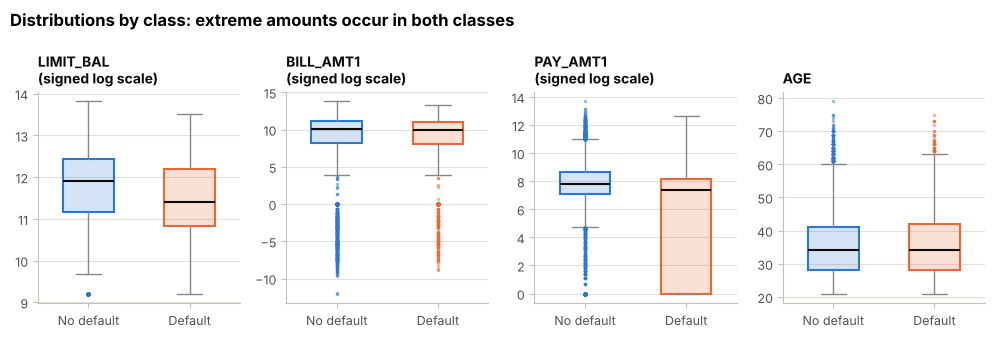

In [18]:
def signed_log(x):
    # sign(x) * log(1 + |x|): compresses large amounts, keeps zero at zero and keeps the sign of negative bills
    return np.sign(x) * np.log1p(np.abs(x))

cols = ['LIMIT_BAL', 'BILL_AMT1', 'PAY_AMT1', 'AGE']
fig, axes = plt.subplots(1, 4, figsize=(10, 3.4))
for ax, col in zip(axes, cols):
    data = [df.loc[df['DEFAULT'] == k, col] for k in (0, 1)]
    if col != 'AGE':
        data = [signed_log(d) for d in data]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops=dict(color=INK, linewidth=1.5),
                    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                    flierprops=dict(marker='o', markersize=2.5, markeredgewidth=0, alpha=0.5))
    for patch, flier, c in zip(bp['boxes'], bp['fliers'], [C_NO, C_YES]):
        patch.set_facecolor(c + '33'); patch.set_edgecolor(c); patch.set_linewidth(1.5); flier.set_markerfacecolor(c)
    ax.set_xticks([1, 2], ['No default', 'Default'])
    ax.grid(axis='x', visible=False)
    ax.set_title(col if col == 'AGE' else f'{col}\n(signed log scale)', fontsize=10)
fig.suptitle('Distributions by class: extreme amounts occur in both classes', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig03_outliers_by_class')
plt.show()

**Finding.** The 1.5 × IQR rule flags 32,670 values. **10,452 clients (34.9%)** have at least one outlying amount. These are mainly clients with **large payments or high limits**, and they default **less** often (15.2% vs 22.1%). The rule is not meaningful here: monetary data are naturally heavy-tailed, and up to 24% of payments are exactly zero.

**Decision: keep all outliers.**
* The values are real and plausible (1.5).
* They are informative: large payments signal low risk.
* Deleting a third of the clients, mostly the reliable ones, would bias the data towards risky clients.
* Their influence on the scale-sensitive models is reduced by transformation (1.7). Tree-based models are insensitive to extreme values because they only use split thresholds.

### 1.7 Skewness, transformation, scaling and encoding

In [19]:
zmax = lambda frame: ((frame - frame.mean()) / frame.std()).abs().max()
skew_table = pd.DataFrame({'skewness (raw)': df[MONEY_COLS].skew(),
                           'skewness (signed log)': signed_log(df[MONEY_COLS]).skew(),
                           'max |z| (raw)': zmax(df[MONEY_COLS]), 'max |z| (signed log)': zmax(signed_log(df[MONEY_COLS])),
                           '% zeros': (df[MONEY_COLS] == 0).mean() * 100}).round(2)
print(f"Median |skewness| of the 13 monetary columns: raw = {skew_table['skewness (raw)'].abs().median():.2f}, "
      f"signed log = {skew_table['skewness (signed log)'].abs().median():.2f}")
print(f"Largest standardised value (|z|): raw = {skew_table['max |z| (raw)'].max():.1f}, "
      f"signed log = {skew_table['max |z| (signed log)'].max():.1f}")
skew_table.sort_values('skewness (raw)', ascending=False)

Median |skewness| of the 13 monetary columns: raw = 3.09, signed log = 1.30
Largest standardised value (|z|): raw = 72.8, signed log = 5.9


,skewness (raw),skewness (signed log),max |z| (raw),max |z| (signed log),% zeros
PAY_AMT2,30.44,-1.24,72.80,2.37,17.90
PAY_AMT3,17.21,-1.08,50.57,2.22,19.81
PAY_AMT1,14.66,-1.30,52.37,2.17,17.41
PAY_AMT4,12.90,-0.97,39.31,2.14,21.28
PAY_AMT5,11.12,-0.94,27.59,2.01,22.27
PAY_AMT6,10.64,-0.86,29.43,2.05,23.83
BILL_AMT3,3.09,-1.86,23.31,5.28,9.48
BILL_AMT5,2.87,-1.69,14.58,4.84,11.60
BILL_AMT6,2.85,-1.56,15.49,4.94,13.32
BILL_AMT4,2.82,-1.78,13.18,5.14,10.56


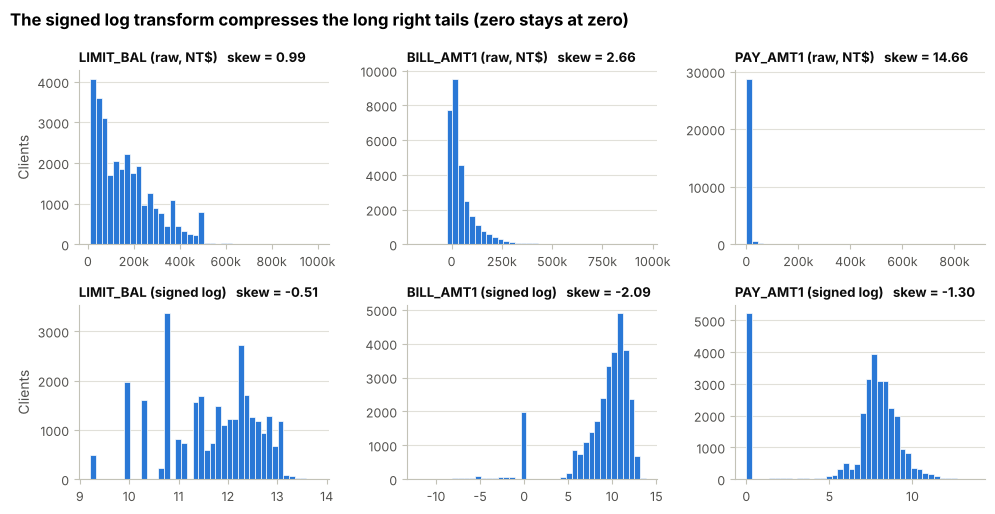

In [20]:
demo = ['LIMIT_BAL', 'BILL_AMT1', 'PAY_AMT1']
fig, axes = plt.subplots(2, 3, figsize=(10, 5.2))
for j, col in enumerate(demo):
    for i, (vals, label) in enumerate([(df[col], 'raw, NT$'), (signed_log(df[col]), 'signed log')]):
        ax = axes[i, j]
        ax.hist(vals, bins=40, color=C_NO, edgecolor='white', linewidth=0.5)
        ax.set_title(f'{col} ({label})   skew = {vals.skew():.2f}', fontsize=9.5)
        ax.grid(axis='x', visible=False)
        if j == 0:
            ax.set_ylabel('Clients')
        ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f'{v/1000:.0f}k' if abs(v) >= 1000 else f'{v:g}'))
fig.suptitle('The signed log transform compresses the long right tails (zero stays at zero)', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig04_signed_log_effect')
plt.show()

**Finding.** The monetary columns are extremely skewed (payments up to skewness 30). The largest payment lies **72.8 standard deviations** above the mean. Such values would dominate the gradient updates of a neural network and the coefficients of a linear model.

**The signed log transform** sign(x) · log(1 + |x|):
* compresses the long tails — the largest |z| falls from 72.8 to 5.9 and the median |skewness| from 3.09 to 1.30;
* keeps zero at zero and keeps the sign of negative bills;
* has no fitted parameters.

The transformed shapes are still not symmetric because of the spike of zero payments. That is acceptable: the goal is to remove extreme leverage, not to force normality.

**Decisions (per algorithm, confirmed by cross-validation in Stage 3).**
* **Neural network:** signed log on the 13 monetary columns, then standardisation of all numeric inputs. Gradient descent needs features on similar scales.
* **Logistic regression:** Yeo-Johnson power transformation + standardisation of all numeric inputs. It fits one exponent per feature, which also makes the relationship of features such as `PAY_k` with the log-odds more linear. Cross-validation preferred it for LR (+0.006 ROC-AUC).
* **Decision tree, random forest and gradient boosting:** raw values. Trees are invariant to monotonic transformations.
* **Encoding (all models):**
  * `EDUCATION` (4 categories) and `MARRIAGE` (3) are nominal → **one-hot encoding**;
  * `SEX` → binary `FEMALE` (1 = female);
  * `PAY_k` stays numeric because it is ordinal.
* All transformers sit **inside each model's pipeline**, so they are fitted on the training folds only.

### 1.8 Feature engineering

In [21]:
def engineer_features(data):
    """Adds the engineered features. Every feature uses only the client's own row (no statistics
    learned from other clients), so it can be computed before the split without any data leakage."""
    out = data.copy()
    limit = out['LIMIT_BAL']
    # credit utilisation: how much of the credit limit is used (clipped to a plausible range)
    out['UTIL_LATEST'] = (out['BILL_AMT1'] / limit).clip(-1, 2)
    out['UTIL_AVG'] = (out[BILL_COLS].mean(axis=1) / limit).clip(-1, 2)
    # repayment ratio: payments Sep-May relative to the bills Aug-Apr they settle (capped at 100%)
    billed = out[BILL_COLS[1:]].clip(lower=0).sum(axis=1)
    paid = out[PAYAMT_COLS[:5]].sum(axis=1)
    out['REPAY_RATIO'] = np.where(billed > 0, paid / billed.where(billed > 0, 1), 1.0).clip(0, 1)
    # payment behaviour over the six months
    out['N_MONTHS_DELAYED'] = (out[PAY_COLS] >= 1).sum(axis=1)
    out['MAX_DELAY'] = out[PAY_COLS].max(axis=1).clip(lower=0)
    # trend of the debt over the six months, relative to the limit
    out['BILL_CHANGE'] = ((out['BILL_AMT1'] - out['BILL_AMT6']) / limit).clip(-2, 2)
    # status indicators for the most recent month (the codes -2 / -1 / 0 are not ordered by risk)
    out['PAY_1_NO_USE'] = (out['PAY_1'] == -2).astype(int)
    out['PAY_1_PAID_FULL'] = (out['PAY_1'] == -1).astype(int)
    out['PAY_1_REVOLVING'] = (out['PAY_1'] == 0).astype(int)
    # binary encoding of SEX (1 = female, 0 = male)
    out['FEMALE'] = (out['SEX'] == 2).astype(int)
    return out.drop(columns='SEX')

ENGINEERED = ['UTIL_LATEST', 'UTIL_AVG', 'REPAY_RATIO', 'N_MONTHS_DELAYED', 'MAX_DELAY', 'BILL_CHANGE']
PAY1_STATUS = ['PAY_1_NO_USE', 'PAY_1_PAID_FULL', 'PAY_1_REVOLVING']
data = engineer_features(df)
clipped = {c: int(((df['BILL_AMT1'] / df['LIMIT_BAL']) if c == 'UTIL_LATEST' else
                   (df[BILL_COLS].mean(axis=1) / df['LIMIT_BAL']) if c == 'UTIL_AVG' else
                   ((df['BILL_AMT1'] - df['BILL_AMT6']) / df['LIMIT_BAL'])).pipe(
                       lambda s: ((s < -1) | (s > 2)) if c != 'BILL_CHANGE' else ((s < -2) | (s > 2))).sum())
           for c in ['UTIL_LATEST', 'UTIL_AVG', 'BILL_CHANGE']}
print('Values changed by clipping:', clipped)
eng_summary = pd.DataFrame({
    'mean (no default)': data.loc[data['DEFAULT'] == 0, ENGINEERED + PAY1_STATUS].mean(),
    'mean (default)': data.loc[data['DEFAULT'] == 1, ENGINEERED + PAY1_STATUS].mean(),
    'correlation with DEFAULT': data[ENGINEERED + PAY1_STATUS].corrwith(data['DEFAULT']),
}).round(3)
eng_summary

Values changed by clipping: {'UTIL_LATEST': 37, 'UTIL_AVG': 15, 'BILL_CHANGE': 17}


,mean (no default),mean (default),correlation with DEFAULT
UTIL_LATEST,0.404,0.490,0.088
UTIL_AVG,0.351,0.450,0.116
REPAY_RATIO,0.408,0.310,-0.100
N_MONTHS_DELAYED,0.504,1.996,0.398
MAX_DELAY,0.470,1.428,0.370
BILL_CHANGE,0.109,0.091,-0.024
PAY_1_NO_USE,0.102,0.055,-0.068
PAY_1_PAID_FULL,0.203,0.144,-0.062
PAY_1_REVOLVING,0.551,0.285,-0.221


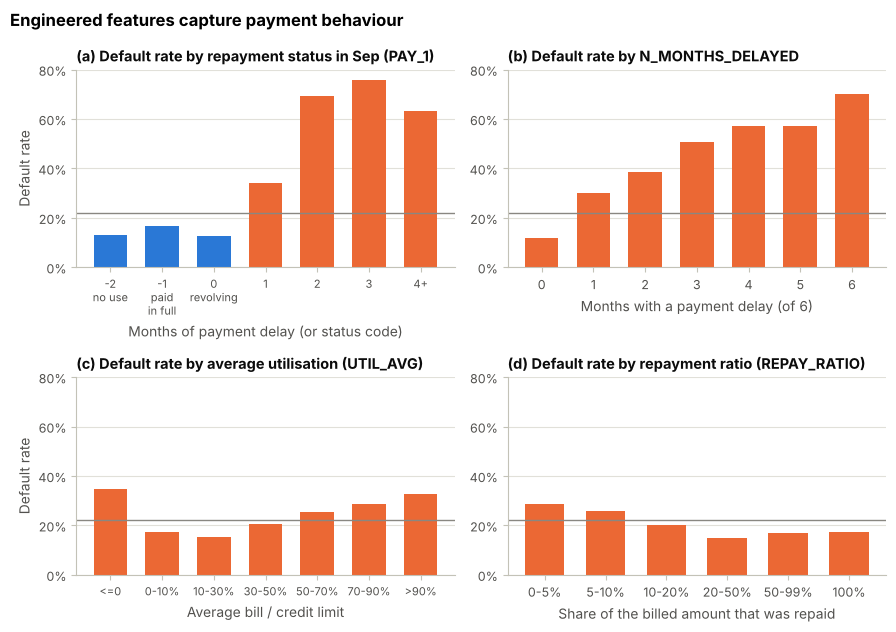

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6.4))
rate = data['DEFAULT'].mean()
# (a) PAY_1 status
g = data.groupby(data['PAY_1'].clip(upper=4))['DEFAULT'].agg(['count', 'mean'])
lab = {-2: '-2\nno use', -1: '-1\npaid\nin full', 0: '0\nrevolving', 1: '1', 2: '2', 3: '3', 4: '4+'}
ax = axes[0, 0]
ax.bar([lab[i] for i in g.index], g['mean'], color=[C_NO if i <= 0 else C_YES for i in g.index], width=0.65)
ax.set_title('(a) Default rate by repayment status in Sep (PAY_1)')
ax.set_xlabel('Months of payment delay (or status code)')
ax.tick_params(axis='x', labelsize=8)
# (b) number of months delayed
g = data.groupby('N_MONTHS_DELAYED')['DEFAULT'].agg(['count', 'mean'])
ax = axes[0, 1]
ax.bar(g.index.astype(str), g['mean'], color=C_YES, width=0.65)
ax.set_title('(b) Default rate by N_MONTHS_DELAYED')
ax.set_xlabel('Months with a payment delay (of 6)')
# (c) utilisation deciles, (d) repayment-ratio groups
ax = axes[1, 0]
bins = [-np.inf, 0, 0.1, 0.3, 0.5, 0.7, 0.9, np.inf]
names = ['<=0', '0-10%', '10-30%', '30-50%', '50-70%', '70-90%', '>90%']
g = data.groupby(pd.cut(data['UTIL_AVG'], bins, labels=names), observed=True)['DEFAULT'].mean()
ax.bar(g.index.astype(str), g.values, color=C_YES, width=0.65)
ax.set_title('(c) Default rate by average utilisation (UTIL_AVG)')
ax.set_xlabel('Average bill / credit limit')
ax.tick_params(axis='x', labelsize=8)
ax = axes[1, 1]
bins = [-0.01, 0.05, 0.1, 0.2, 0.5, 0.99, 1.0]
names = ['0-5%', '5-10%', '10-20%', '20-50%', '50-99%', '100%']
g = data.groupby(pd.cut(data['REPAY_RATIO'], bins, labels=names), observed=True)['DEFAULT'].mean()
ax.bar(g.index.astype(str), g.values, color=C_YES, width=0.65)
ax.set_title('(d) Default rate by repayment ratio (REPAY_RATIO)')
ax.set_xlabel('Share of the billed amount that was repaid')
for ax in axes.flat:
    ax.axhline(rate, color=MUTED, linewidth=1)
    ax.grid(axis='x', visible=False)
    pct_axis(ax)
    ax.set_ylim(0, 0.8)
axes[0, 0].set_ylabel('Default rate'); axes[1, 0].set_ylabel('Default rate')
fig.suptitle('Engineered features capture payment behaviour', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig05_engineered_features')
plt.show()

Nine features were added, based on how lenders assess credit risk. All are computed from the client's own row only, so they cannot leak information between clients or between the data splits.

| Feature | Definition | Why |
|---|---|---|
| `UTIL_LATEST`, `UTIL_AVG` | September bill / limit, and average bill / limit (clipped to [−1, 2]) | **Credit utilisation**: the bills mean little without the limit |
| `REPAY_RATIO` | payments Sep–May / positive bills Aug–Apr (capped at 100%) | Share of the debt that is actually repaid (a payment in month *k* settles the bill of month *k + 1*) |
| `N_MONTHS_DELAYED` | number of months (of 6) with a payment delay | Persistence of payment problems |
| `MAX_DELAY` | longest delay in months | Severity of payment problems |
| `BILL_CHANGE` | (Sep bill − Apr bill) / limit (clipped to [−2, 2]) | Is the debt growing? |
| `PAY_1_NO_USE`, `PAY_1_PAID_FULL`, `PAY_1_REVOLVING` | indicators for status −2 / −1 / 0 in September | The unordered status codes (Fig. 5a) |

**Patterns (Figure 5).**
* **(a)** The September status is non-monotonic: −1 (paid in full) has a *higher* default rate (16.8%) than −2 (13.2%) or 0 (12.8%). Any delay raises the risk sharply (34% for one month, 69% for two). A single numeric column cannot express this to a linear model; the indicators can.
* **(b)** `N_MONTHS_DELAYED` increases steadily, from 11.7% default with no delay to 70.3% with six delayed months. Its correlation with `DEFAULT` (r = 0.398) is the **highest of all features**.
* **(c)** Utilisation shows a U-shape: both very low and very high utilisation are riskier.
* **(d)** Clients who repay a larger share of their bills default less.

Clipping changed only 69 values in total.

### 1.9 Correlation and multicollinearity

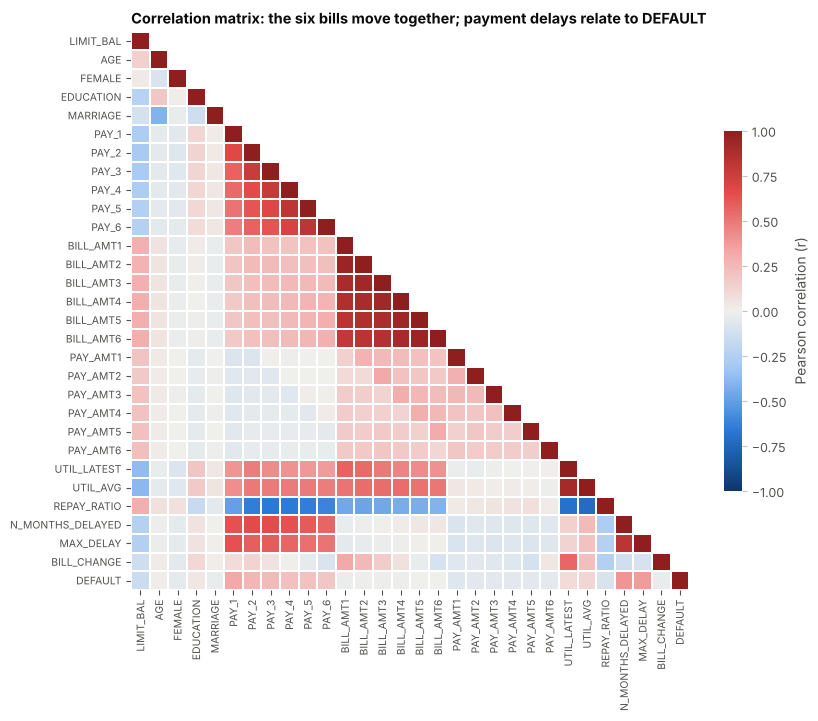

Correlation range among BILL_AMT1-6 : (np.float64(0.803), np.float64(0.951))
Correlation range among PAY_1-6     : (np.float64(0.475), np.float64(0.819))
Correlation range among PAY_AMT1-6  : (np.float64(0.148), np.float64(0.286))
Top correlations with DEFAULT:


N_MONTHS_DELAYED    0.398
MAX_DELAY           0.370
PAY_1               0.325
PAY_2               0.264
PAY_3               0.235
PAY_4               0.217
PAY_5               0.204
PAY_6               0.187
Name: DEFAULT, dtype: float64

In [23]:
num_cols = ['LIMIT_BAL', 'AGE', 'FEMALE', 'EDUCATION', 'MARRIAGE'] + PAY_COLS + BILL_COLS + PAYAMT_COLS + ENGINEERED
corr = data[num_cols + ['DEFAULT']].corr()
fig, ax = plt.subplots(figsize=(9, 7.8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, square=True, linewidths=0.3, linecolor='white',
            cbar_kws={'shrink': 0.6, 'label': 'Pearson correlation (r)'}, ax=ax)
ax.grid(False)
ax.tick_params(labelsize=7.5, colors=INK2)
ax.set_title('Correlation matrix: the six bills move together; payment delays relate to DEFAULT')
save_fig(fig, 'fig06_correlation_heatmap')
plt.show()

def offdiag_range(cols):
    m = data[cols].corr().where(~np.eye(len(cols), dtype=bool)).stack()
    return round(m.min(), 3), round(m.max(), 3)
print('Correlation range among BILL_AMT1-6 :', offdiag_range(BILL_COLS))
print('Correlation range among PAY_1-6     :', offdiag_range(PAY_COLS))
print('Correlation range among PAY_AMT1-6  :', offdiag_range(PAYAMT_COLS))
print('Top correlations with DEFAULT:')
corr['DEFAULT'].drop('DEFAULT').sort_values(key=abs, ascending=False).head(8).round(3)

In [24]:
def variance_inflation(frame):
    # VIF_j = 1 / (1 - R^2_j), R^2_j from regressing feature j on all other features
    Z = (frame - frame.mean()) / frame.std()
    out = {}
    for col in Z.columns:
        others = Z.drop(columns=col)
        r2 = LinearRegression().fit(others, Z[col]).score(others, Z[col])
        out[col] = 1.0 / (1.0 - r2)
    return pd.Series(out)

vif_cols = ['LIMIT_BAL', 'AGE'] + PAY_COLS + BILL_COLS + PAYAMT_COLS + ENGINEERED
vif_input = data[vif_cols].copy()
vif_input[['LIMIT_BAL'] + BILL_COLS + PAYAMT_COLS] = signed_log(vif_input[['LIMIT_BAL'] + BILL_COLS + PAYAMT_COLS])
vif = variance_inflation(vif_input).sort_values(ascending=False)
print(f'Features with VIF > 10: {int((vif > 10).sum())} of {len(vif)}; median VIF = {vif.median():.1f}')
vif.round(1).head(10).to_frame('VIF')

Features with VIF > 10: 2 of 26; median VIF = 5.7


,VIF
UTIL_LATEST,36.2
UTIL_AVG,26.9
PAY_5,7.2
PAY_4,6.8
BILL_CHANGE,6.4
BILL_AMT3,6.4
BILL_AMT6,6.4
PAY_3,6.4
BILL_AMT2,6.2
BILL_AMT4,6.2


**Findings.**
* The six monthly bills are strongly correlated (r = 0.80–0.95), and so are the repayment statuses (r = 0.48–0.82). Payments are only weakly correlated (r = 0.15–0.29).
* On the log scale, the variance inflation factors are moderate (median 5.7). Only the two utilisation features exceed 10 (VIF 36 and 27), because they are ratios of amounts that are also in the model.

**Decision: keep all features.**
* With 20,975 training clients and 37 inputs, there is plenty of data per parameter.
* LR and the NN use L2 regularisation, which stabilises correlated coefficients.
* Tree models are unaffected by collinearity.
* Cross-validation (Stage 3) shows that the engineered features *improve* every model.

### 1.10 Most relevant features

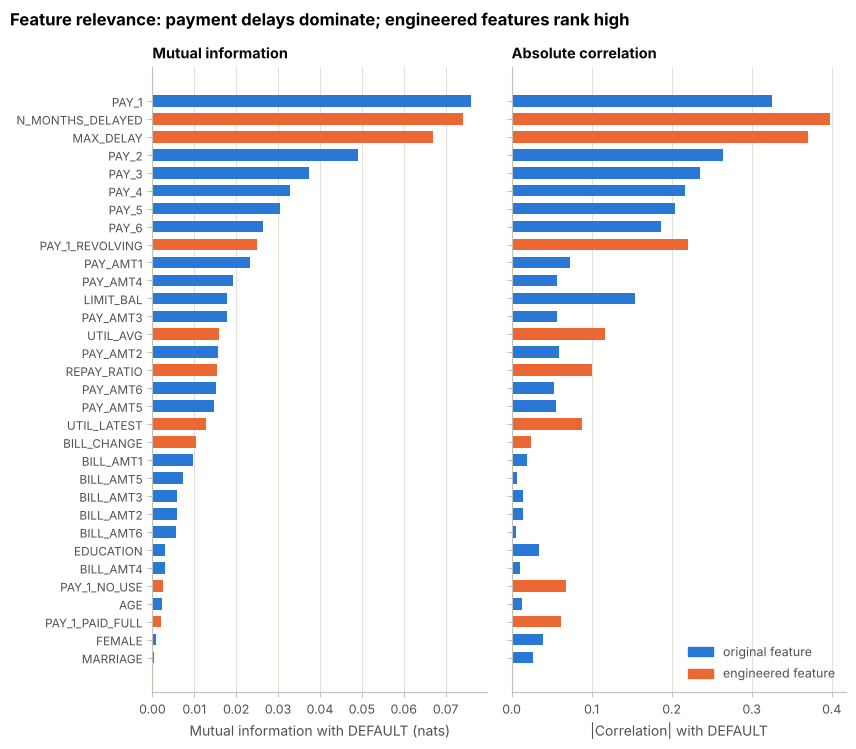

,mutual information,r with DEFAULT,|r|,group
PAY_1,0.0761,0.3250,0.3250,original
N_MONTHS_DELAYED,0.0741,0.3984,0.3984,engineered
MAX_DELAY,0.0669,0.3704,0.3704,engineered
PAY_2,0.0491,0.2637,0.2637,original
PAY_3,0.0373,0.2352,0.2352,original
PAY_4,0.0329,0.2166,0.2166,original
PAY_5,0.0305,0.2041,0.2041,original
PAY_6,0.0264,0.1867,0.1867,original
PAY_1_REVOLVING,0.0251,-0.2207,0.2207,engineered
PAY_AMT1,0.0232,-0.0730,0.0730,original


In [25]:
FEATURES = ['LIMIT_BAL', 'FEMALE', 'EDUCATION', 'MARRIAGE', 'AGE'] + PAY_COLS + BILL_COLS + PAYAMT_COLS + ENGINEERED + PAY1_STATUS
discrete = [c in ['FEMALE', 'EDUCATION', 'MARRIAGE', 'N_MONTHS_DELAYED', 'MAX_DELAY'] + PAY_COLS + PAY1_STATUS for c in FEATURES]
mi = pd.Series(mutual_info_classif(data[FEATURES], data['DEFAULT'], discrete_features=discrete,
                                   random_state=RANDOM_STATE), index=FEATURES)
r_pb = data[FEATURES].corrwith(data['DEFAULT'])
relevance = pd.DataFrame({'mutual information': mi, 'r with DEFAULT': r_pb, '|r|': r_pb.abs()}) \
    .sort_values('mutual information', ascending=False)
relevance['group'] = ['engineered' if c in ENGINEERED + PAY1_STATUS else 'original' for c in relevance.index]

fig, axes = plt.subplots(1, 2, figsize=(8.6, 7.6), sharey=True)
order = relevance.index[::-1]
colors = [C_YES if relevance.loc[c, 'group'] == 'engineered' else C_NO for c in order]
axes[0].barh(order, relevance.loc[order, 'mutual information'], color=colors, height=0.65)
axes[0].set_xlabel('Mutual information with DEFAULT (nats)')
axes[0].set_title('Mutual information')
axes[1].barh(order, relevance.loc[order, '|r|'], color=colors, height=0.65)
axes[1].set_xlabel('|Correlation| with DEFAULT')
axes[1].set_title('Absolute correlation')
for ax in axes:
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', labelsize=8.5)
axes[1].legend(handles=[Patch(color=C_NO, label='original feature'), Patch(color=C_YES, label='engineered feature')],
               loc='lower right')
fig.suptitle('Feature relevance: payment delays dominate; engineered features rank high', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig07_feature_relevance')
plt.show()
relevance.head(12).round(4)

**Most relevant features.** Mutual information and correlation agree:
* **Payment behaviour dominates.** The top features are `PAY_1` (MI 0.076), `N_MONTHS_DELAYED`, `MAX_DELAY` and the earlier statuses `PAY_2`–`PAY_6`, followed by `PAY_1_REVOLVING`, recent payment amounts and `LIMIT_BAL` (r = −0.154: higher limits mean lower risk).
* **Bill amounts are almost unrelated to default on their own** (|r| < 0.02). They become useful only relative to the limit (utilisation).
* **Personal attributes carry very little information** (MI < 0.003 for sex, marital status and age).

All features are kept: none is harmful, and Stage 3 tests what happens without the personal attributes.

### 1.11 Summary of the preparation decisions

| Step | Finding | Decision |
|---|---|---|
| Missing values | none; undocumented codes in `EDUCATION` / `MARRIAGE` | treated as inconsistent data (below) |
| Duplicates | 35 exact duplicate rows; 21 same-feature groups with different targets | remove the 35 duplicates; keep the rest; drop `ID` |
| Inconsistent data | codes 0/5/6 (`EDUCATION`), 0 (`MARRIAGE`), undocumented −2/0 in `PAY_k`, `PAY_0` naming | merge into "others"; interpret and keep the `PAY_k` codes; rename to `PAY_1 … PAY_6` |
| Outliers | 34.9% of clients flagged; mostly reliable high-payment clients | keep; reduce their leverage by transformation |
| Target | 22.1% default (3.52 : 1) | stratified splits, class weights tested, threshold tuned on validation data |
| Encoding | 2 nominal features, 1 binary | one-hot `EDUCATION` / `MARRIAGE`; `FEMALE` = 1/0 |
| Scaling | skewness up to 30, values up to 73 SD | NN: signed log + standardisation; LR: Yeo-Johnson + standardisation; trees: none |
| Feature engineering | utilisation, repayment ratio, delay counts, status indicators | 9 new features → 32 feature columns (37 model inputs) |
| Relevance | payment history dominates; personal attributes weak | keep all; check removal of personal attributes |

---
## Stage 2 — Data Splitting

In [26]:
X_all, y_all = data[FEATURES], data['DEFAULT']
# 15% test set first, then 15% of the total as validation set; stratified on the target
X_temp, X_test, y_temp, y_test = train_test_split(X_all, y_all, test_size=0.15, stratify=y_all,
                                                  random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp,
                                                  random_state=RANDOM_STATE)
split_summary = pd.DataFrame({
    'clients': [len(y_train), len(y_val), len(y_test)],
    '% of data': [round(100 * len(s) / len(y_all), 1) for s in (y_train, y_val, y_test)],
    'defaults': [int(s.sum()) for s in (y_train, y_val, y_test)],
    'no default': [int((s == 0).sum()) for s in (y_train, y_val, y_test)],
    '% default': [round(100 * s.mean(), 2) for s in (y_train, y_val, y_test)],
}, index=['Training', 'Validation', 'Test'])
split_summary.loc['Total'] = [len(y_all), 100.0, int(y_all.sum()), int((y_all == 0).sum()), round(100 * y_all.mean(), 2)]
split_summary.to_csv('results/split_summary.csv')
assert not (set(X_train.index) & set(X_val.index)) and not (set(X_train.index) & set(X_test.index)) \
    and not (set(X_val.index) & set(X_test.index)), 'the three sets must not overlap'
split_summary

,clients,% of data,defaults,no default,% default
Training,20975.0,70.0,4641.0,16334.0,22.13
Validation,4495.0,15.0,994.0,3501.0,22.11
Test,4495.0,15.0,995.0,3500.0,22.14
Total,29965.0,100.0,6630.0,23335.0,22.13


**Chosen partition: 70% training / 15% validation / 15% test, stratified** → 20,975 / 4,495 / 4,495 clients, each with 22.1% defaults.

**Justification.**
* **Large dataset.** 15% already gives about **995 defaulters per evaluation set**. That is enough for precise estimates: the bootstrap 95% interval for the test ROC-AUC is about ±0.018 (Stage 5).
* **The validation set has two jobs.** It is used for early stopping of the neural network and for choosing each model's decision threshold. Both need enough defaulters, which argues against a smaller set (80/10/10 would leave about 660).
* **Enough training data.** 70% (20,975 clients) is plenty for 5-fold cross-validation, where each fold still trains on 16,780 clients. The learning curves (Stage 4) show the models have almost reached their plateau, so a larger training share would add little.
* **Stratification** keeps the default rate identical in all three sets.

**Roles of the three sets.**
* **Training set** — fit the models and tune the hyperparameters with 5-fold cross-validation inside the training set.
* **Validation set** — check over-/under-fitting, early-stop the NN and choose the decision thresholds.
* **Test set** — used **once**, for the final comparison.

The split is made **before** any model is fitted, with a fixed seed, and an assertion checks that the sets do not overlap.

---
## Stage 3 — Model Selection and Development

The target is binary, so this is a **classification** problem; Linear Regression is not appropriate. Five models of increasing flexibility are compared, including the mandatory neural network:

| Model | Family | Why it suits this problem | Inputs |
|---|---|---|---|
| **Logistic Regression** | linear, probabilistic | Standard credit-scoring model. Interpretable coefficients and probability outputs; strong baseline. | Yeo-Johnson + scaled |
| **Decision Tree** | rule-based | Human-readable rules; captures interactions (e.g. delay × utilisation); no scaling needed. Also a high-variance reference. | raw |
| **Random Forest** | ensemble (bagging) | Averages hundreds of decorrelated trees: non-linear, robust to outliers and correlated features. | raw |
| **Gradient Boosting** | ensemble (boosting) | `HistGradientBoostingClassifier`: adds shallow trees that correct the previous errors. Usually the strongest model family for tabular data; fast on 21k rows. | raw |
| **Neural Network (MLP)** | feed-forward network | Mandatory. Learns non-linear feature combinations; regularised with L2 and early stopping. | signed log + scaled |

**Not selected: SVM.** Kernel SVMs need roughly O(n²) memory and O(n²–n³) training time, which is impractical for a grid search on 21,000 clients. They also give no probabilities without extra calibration. The tree ensembles already provide flexible non-linear decision boundaries.

**Neural network design.**
* **Input:** 37 inputs.
* **Hidden layers:** fully connected, ReLU; the number of layers and neurons and the L2 penalty `alpha` are tuned in Stage 4.
* **Output:** one sigmoid unit giving P(default).
* **Training:** **Adam** optimiser, **binary cross-entropy** loss, mini-batches of 256.

Every model is a `Pipeline` of its preprocessing and the classifier, so cross-validation re-fits the preprocessing inside each fold.

In [27]:
CAT_COLS = ['EDUCATION', 'MARRIAGE']
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'roc_auc': 'roc_auc', 'ap': 'average_precision'}

def make_preprocessor(kind, columns):
    """kind: 'signed-log' (final choice), 'standard', 'yeo-johnson' or 'trees' (no scaling)."""
    money = [c for c in MONEY_COLS if c in columns]
    cat = [c for c in CAT_COLS if c in columns]
    other = [c for c in columns if c not in money + cat]
    if kind == 'signed-log':
        money_tf = Pipeline([('log', FunctionTransformer(signed_log, feature_names_out='one-to-one')),
                             ('scale', StandardScaler())])
        other_tf = StandardScaler()
    elif kind == 'standard':
        money_tf, other_tf = StandardScaler(), StandardScaler()
    elif kind == 'yeo-johnson':
        money_tf, other_tf = PowerTransformer(method='yeo-johnson'), PowerTransformer(method='yeo-johnson')
    elif kind == 'trees':
        money_tf, other_tf = 'passthrough', 'passthrough'
    return ColumnTransformer([('money', money_tf, money), ('other', other_tf, other),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)],
                             verbose_feature_names_out=False)

PREP_KIND = {'Logistic Regression': 'yeo-johnson', 'Decision Tree': 'trees', 'Random Forest': 'trees',
             'Gradient Boosting': 'trees', 'Neural Network': 'signed-log'}

def make_pipeline(name, clf, columns=FEATURES, kind=None):
    return Pipeline([('prep', make_preprocessor(kind or PREP_KIND[name], columns)), ('clf', clf)])

def base_estimators():
    # default (untuned) settings = the starting point before hyperparameter optimisation
    return {
        'Logistic Regression': LogisticRegression(max_iter=10000),
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
        'Gradient Boosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        'Neural Network': MLPClassifier(random_state=RANDOM_STATE, max_iter=200),
    }

n_inputs = make_preprocessor('signed-log', FEATURES).fit(X_train).transform(X_train.head()).shape[1]
print(f'{len(FEATURES)} feature columns -> {n_inputs} model inputs after one-hot encoding of EDUCATION and MARRIAGE')

32 feature columns -> 37 model inputs after one-hot encoding of EDUCATION and MARRIAGE


### 3.1 Baseline with default hyperparameters

In [28]:
def cv_summary(estimator, X, y, cv=CV):
    r = cross_validate(estimator, X, y, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    return {'CV ROC-AUC': r['test_roc_auc'].mean(), 'CV ROC-AUC (sd)': r['test_roc_auc'].std(),
            'CV PR-AUC': r['test_ap'].mean(), 'Train ROC-AUC': r['train_roc_auc'].mean(),
            'Gap (train - CV)': r['train_roc_auc'].mean() - r['test_roc_auc'].mean(),
            'Fit time (s)': r['fit_time'].mean()}

t0 = time.time()
baseline = pd.DataFrame({name: cv_summary(make_pipeline(name, clf), X_train, y_train)
                         for name, clf in base_estimators().items()}).T
baseline.to_csv('results/baseline_cv.csv')
print(f'({time.time() - t0:.0f}s)')
baseline.round(4)

(71s)


,CV ROC-AUC,CV ROC-AUC (sd),CV PR-AUC,Train ROC-AUC,Gap (train - CV),Fit time (s)
Logistic Regression,0.7808,0.0043,0.5363,0.7830,0.0022,1.2149
Decision Tree,0.6181,0.0116,0.2945,1.0000,0.3819,0.4358
Random Forest,0.7714,0.0049,0.5416,1.0000,0.2286,9.0987
Gradient Boosting,0.7864,0.0049,0.5580,0.8634,0.0770,0.3624
Neural Network,0.7483,0.0055,0.5003,0.8792,0.1309,11.2461


**Observations.**
* With default settings, the **decision tree** fits the training data perfectly (ROC-AUC 1.000) but reaches only **0.618** in cross-validation — extreme **over-fitting**.
* The default **random forest** also memorises the training set (1.000 vs 0.771).
* The default **neural network** (100 neurons, no early stopping, weak L2) over-fits as well (0.879 vs 0.748).
* Logistic regression shows no gap (0.783 vs 0.781): it is limited by its linear form, not by variance.
* Default gradient boosting is already the best model (0.786).

### 3.2 Testing the Stage 1 decisions with cross-validation

In [29]:
ORIGINAL = ['LIMIT_BAL', 'FEMALE', 'EDUCATION', 'MARRIAGE', 'AGE'] + PAY_COLS + BILL_COLS + PAYAMT_COLS
FEATURE_SETS = {'original (23)': ORIGINAL, '+ engineered (29)': ORIGINAL + ENGINEERED,
                '+ engineered + PAY_1 status (32)': FEATURES}
ABLATION_MODELS = {
    'Logistic Regression': LogisticRegression(max_iter=10000),
    'Neural Network': MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=256, early_stopping=True,
                                    max_iter=300, random_state=RANDOM_STATE),
}
rows, t0 = [], time.time()
for fs_name, cols in FEATURE_SETS.items():
    for name, clf in ABLATION_MODELS.items():
        for kind in ['standard', 'yeo-johnson', 'signed-log']:
            r = cross_validate(make_pipeline(name, clf, cols, kind), X_train[cols], y_train, cv=CV, scoring=SCORING, n_jobs=-1)
            rows.append({'features': fs_name, 'model': name, 'scaling': kind,
                         'CV ROC-AUC': r['test_roc_auc'].mean(), 'CV PR-AUC': r['test_ap'].mean()})
    r = cross_validate(make_pipeline('Gradient Boosting', HistGradientBoostingClassifier(random_state=RANDOM_STATE), cols),
                       X_train[cols], y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    rows.append({'features': fs_name, 'model': 'Gradient Boosting', 'scaling': 'none (trees)',
                 'CV ROC-AUC': r['test_roc_auc'].mean(), 'CV PR-AUC': r['test_ap'].mean()})
ablation = pd.DataFrame(rows)
ablation.to_csv('results/preprocessing_ablation.csv', index=False)
print(f'({time.time() - t0:.0f}s)')
ablation.pivot_table(index=['model', 'scaling'], columns='features', values='CV ROC-AUC', sort=False).round(4)

(58s)


features                          original (23)  + engineered (29)  + engineered + PAY_1 status (32)
model               scaling                                                                         
Logistic Regression standard             0.7274             0.7655                            0.7733
                    yeo-johnson          0.7490             0.7641                            0.7808
                    signed-log           0.7500             0.7635                            0.7750
Neural Network      standard             0.7753             0.7784                            0.7784
                    yeo-johnson          0.7760             0.7803                            0.7820
                    signed-log           0.7750             0.7822                            0.7829
Gradient Boosting   none (trees)         0.7805             0.7866                            0.7864

**Results (training set, 5-fold CV).**
* **Engineered features help every model.** LR improves by +0.013 to +0.038, the NN by +0.003 to +0.007 and gradient boosting by +0.006.
* **The `PAY_1` status indicators** add a further +0.008 to +0.017 for LR, which cannot learn the non-monotonic pattern itself. GB and the NN learn it from the raw codes, so for them the indicators change little (GB −0.0002, NN 0 to +0.002).
* **Transformation choice (final feature set):**
  * LR is best with **Yeo-Johnson** (0.7808, vs 0.7750 with the signed log and 0.7733 with plain standardisation).
  * The NN is best with the **signed log** (0.7829, vs 0.7820 and 0.7784).
* These are the choices used in the pipelines.

In [30]:
# Sensitivity check: what happens without the personal attributes sex, age and marital status?
PERSONAL = ['FEMALE', 'AGE', 'MARRIAGE']
no_personal = [c for c in FEATURES if c not in PERSONAL]
fair_rows = []
for name, clf in [('Logistic Regression', LogisticRegression(max_iter=10000)),
                  ('Gradient Boosting', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]:
    for label, cols in [('all 32 features', FEATURES), ('without sex, age, marital status', no_personal)]:
        r = cross_validate(make_pipeline(name, clf, cols), X_train[cols], y_train, cv=CV, scoring=SCORING, n_jobs=-1)
        fair_rows.append({'model': name, 'features': label, 'CV ROC-AUC': r['test_roc_auc'].mean(),
                          'CV PR-AUC': r['test_ap'].mean()})
fairness = pd.DataFrame(fair_rows)
fairness.to_csv('results/personal_attributes_check.csv', index=False)
fairness.round(4)

,model,features,CV ROC-AUC,CV PR-AUC
0,Logistic Regression,all 32 features,0.7808,0.5363
1,Logistic Regression,"without sex, age, marital status",0.7794,0.5355
2,Gradient Boosting,all 32 features,0.7864,0.5580
3,Gradient Boosting,"without sex, age, marital status",0.7862,0.5606


**Personal attributes.** Removing sex, age and marital status lowers the CV ROC-AUC by only 0.0014 (LR) and 0.0002 (GB). In many countries these attributes may not be used for credit decisions. We keep them in the main models to stay with the full dataset, and discuss the implications in Section 6.

---
## Stage 4 — Model Training and Hyperparameter Optimisation

### 4.1 Hyperparameter search
* **Method:** exhaustive `GridSearchCV` with **stratified 5-fold cross-validation** on the training set (16,780 training clients per fold). Then the best configuration of each model is refitted on the full training set.
* **Selection metric: ROC-AUC.**
  * It measures how well the model *ranks* defaulters above non-defaulters, independent of the decision threshold, which is tuned separately.
  * It does not depend on the class ratio.
  * It is the standard metric in credit scoring (Gini = 2 · AUC − 1).
* PR-AUC is recorded for every candidate as well.
* **Grids** cover each model's capacity and regularisation controls. The NN grid spans 5 architectures × 7 L2 strengths. Inside the search the NN uses early stopping on an internal 10% split.

In [31]:
def tuned_estimators():
    return {
        'Logistic Regression': LogisticRegression(max_iter=10000),
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=200, max_features='sqrt', random_state=RANDOM_STATE, n_jobs=1),
        'Gradient Boosting': HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                                            n_iter_no_change=20, random_state=RANDOM_STATE),
        'Neural Network': MLPClassifier(activation='relu', solver='adam', learning_rate_init=1e-3, batch_size=256,
                                        early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                                        max_iter=300, random_state=RANDOM_STATE),
    }

PARAM_GRIDS = {
    'Logistic Regression': {'clf__C': [1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100], 'clf__class_weight': [None, 'balanced']},
    'Decision Tree': {'clf__max_depth': [4, 6, 8, 10, 12, None], 'clf__min_samples_leaf': [1, 50, 100, 200, 400, 800],
                      'clf__class_weight': [None, 'balanced']},
    'Random Forest': {'clf__max_depth': [12, None], 'clf__min_samples_leaf': [5, 15, 30, 60],
                      'clf__class_weight': [None, 'balanced_subsample']},
    'Gradient Boosting': {'clf__learning_rate': [0.03, 0.1], 'clf__max_leaf_nodes': [7, 15, 31],
                          'clf__min_samples_leaf': [50, 200, 800], 'clf__l2_regularization': [0.0, 10.0, 100.0]},
    'Neural Network': {'clf__hidden_layer_sizes': [(32,), (64, 32), (128, 64), (128, 64, 32), (256, 128, 64)],
                       'clf__alpha': [1e-4, 1e-3, 1e-2, 0.1, 1.0, 3.0, 10.0]},
}

searches, tuning_time = {}, {}
for name, clf in tuned_estimators().items():
    t0 = time.time()
    gs = GridSearchCV(make_pipeline(name, clf), PARAM_GRIDS[name], cv=CV, scoring=SCORING, refit='roc_auc', n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name], tuning_time[name] = gs, time.time() - t0
    print(f'{name:<20} {len(gs.cv_results_["params"]):>3} configurations x 5 folds -> best CV ROC-AUC '
          f'{gs.best_score_:.4f}  ({tuning_time[name]:.0f}s)')

Logistic Regression   14 configurations x 5 folds -> best CV ROC-AUC 0.7833  (46s)
Decision Tree         72 configurations x 5 folds -> best CV ROC-AUC 0.7777  (40s)
Random Forest         16 configurations x 5 folds -> best CV ROC-AUC 0.7909  (278s)
Gradient Boosting     54 configurations x 5 folds -> best CV ROC-AUC 0.7909  (124s)
Neural Network        35 configurations x 5 folds -> best CV ROC-AUC 0.7844  (209s)


In [32]:
def clean_params(p):
    return ', '.join(f"{k.replace('clf__', '')}={v}" for k, v in p.items())

tuning_rows = []
for name, gs in searches.items():
    i, res = gs.best_index_, gs.cv_results_
    tuning_rows.append({'Model': name, 'Best hyperparameters': clean_params(gs.best_params_), 'Configs': len(res['params']),
                        'CV ROC-AUC': res['mean_test_roc_auc'][i], 'CV ROC-AUC (sd)': res['std_test_roc_auc'][i],
                        'CV PR-AUC': res['mean_test_ap'][i], 'Tuning time (s)': tuning_time[name]})
tuning_summary = pd.DataFrame(tuning_rows).set_index('Model')
tuning_summary.to_csv('results/tuning_summary.csv')
best_params = {name: {k.replace('clf__', ''): (list(v) if isinstance(v, tuple) else v) for k, v in gs.best_params_.items()}
               for name, gs in searches.items()}
with open('results/best_params.json', 'w') as f:
    json.dump(best_params, f, indent=2, default=str)
tuning_summary.round(4)

,Best hyperparameters,Configs,CV ROC-AUC,CV ROC-AUC (sd),CV PR-AUC,Tuning time (s)
Model,,,,,,
Logistic Regression,"C=100, class_weight=balanced",14,0.7833,0.0044,0.5373,45.7266
Decision Tree,"class_weight=balanced, max_depth=10, min_sampl...",72,0.7777,0.0067,0.5333,40.3256
Random Forest,"class_weight=balanced_subsample, max_depth=12,...",16,0.7909,0.0048,0.5631,278.4878
Gradient Boosting,"l2_regularization=100.0, learning_rate=0.03, m...",54,0.7909,0.0041,0.5618,123.5262
Neural Network,"alpha=1.0, hidden_layer_sizes=(128, 64, 32)",35,0.7844,0.0063,0.5469,208.9276


In [33]:
top_rows = []
for name, gs in searches.items():
    res = pd.DataFrame(gs.cv_results_).sort_values('rank_test_roc_auc')
    print(f'--- {name}')
    for rank, (_, row) in enumerate(res.head(5).iterrows(), start=1):
        print(f"   AUC {row['mean_test_roc_auc']:.4f} +/- {row['std_test_roc_auc']:.4f} | PR-AUC {row['mean_test_ap']:.4f} | "
              f"{clean_params(row['params'])}")
        top_rows.append({'model': name, 'rank': rank, 'CV ROC-AUC': row['mean_test_roc_auc'],
                         'sd': row['std_test_roc_auc'], 'CV PR-AUC': row['mean_test_ap'], 'params': clean_params(row['params'])})
    spread = res['mean_test_roc_auc'].iloc[0] - res['mean_test_roc_auc'].iloc[min(4, len(res) - 1)]
    print(f'   -> top-5 spread: {spread:.4f}')
pd.DataFrame(top_rows).to_csv('results/top_configurations.csv', index=False)

--- Logistic Regression
   AUC 0.7833 +/- 0.0044 | PR-AUC 0.5373 | C=100, class_weight=balanced
   AUC 0.7833 +/- 0.0045 | PR-AUC 0.5371 | C=10, class_weight=balanced
   AUC 0.7832 +/- 0.0045 | PR-AUC 0.5369 | C=1, class_weight=balanced
   AUC 0.7824 +/- 0.0046 | PR-AUC 0.5344 | C=0.1, class_weight=balanced
   AUC 0.7809 +/- 0.0044 | PR-AUC 0.5365 | C=100, class_weight=None
   -> top-5 spread: 0.0025
--- Decision Tree
   AUC 0.7777 +/- 0.0067 | PR-AUC 0.5333 | class_weight=balanced, max_depth=10, min_samples_leaf=400
   AUC 0.7777 +/- 0.0067 | PR-AUC 0.5333 | class_weight=balanced, max_depth=12, min_samples_leaf=400
   AUC 0.7777 +/- 0.0067 | PR-AUC 0.5333 | class_weight=balanced, max_depth=None, min_samples_leaf=400
   AUC 0.7775 +/- 0.0066 | PR-AUC 0.5331 | class_weight=balanced, max_depth=8, min_samples_leaf=400
   AUC 0.7765 +/- 0.0063 | PR-AUC 0.5313 | class_weight=balanced, max_depth=6, min_samples_leaf=400
   -> top-5 spread: 0.0012
--- Random Forest
   AUC 0.7909 +/- 0.0048 | P

**Selected hyperparameters.**

| Model | Selected | Reasoning |
|---|---|---|
| Logistic Regression | C = 100, class_weight = balanced | The CV score is flat for C ≥ 1 (0.7832–0.7833). With 20,975 clients the model does not over-fit, so little regularisation is needed. Balanced weights gained +0.0024. |
| Decision Tree | max_depth = 10, min_samples_leaf = 400, balanced | Very large leaves (≥ 400 clients) are the key regularisation; 800 and more under-fit. Depths ≥ 10 tie. |
| Random Forest | 200 trees, √p features, max_depth = 12, min_samples_leaf = 30, balanced_subsample | Leaves of 30 clients smooth the individual trees; the top configurations are within 0.0004. |
| Gradient Boosting | learning_rate = 0.03, max_leaf_nodes = 31, min_samples_leaf = 200, l2 = 100, early stopping (194 rounds) | A small learning rate with early stopping; the top-5 differ by only 0.0002. |
| Neural Network | 3 hidden layers (128-64-32), ReLU, alpha = 1.0, Adam (lr 0.001), batch 256 | Strong L2 regularisation wins. The five best networks are within 0.0008. |

For every model, the best configurations are within a fraction of one fold standard deviation (≈0.004–0.007) of each other. Performance is therefore **robust** near the optimum, rather than the result of a lucky grid point.

### 4.2 Validation curves: where does over-/under-fitting start?

(237s)


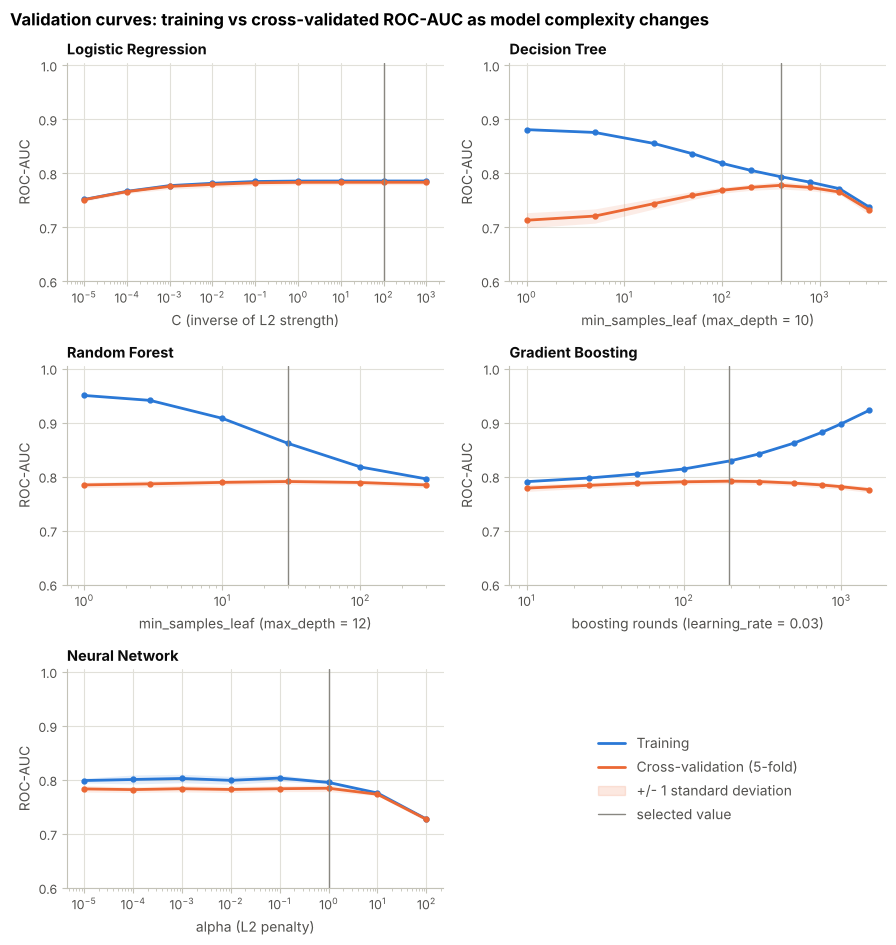

Gradient boosting rounds chosen by early stopping: 194


In [34]:
dt_depth = searches['Decision Tree'].best_params_['clf__max_depth']
rf_depth = searches['Random Forest'].best_params_['clf__max_depth']
VC_SPECS = {
    'Logistic Regression': ('clf__C', np.logspace(-5, 3, 9), 'C (inverse of L2 strength)', 'log'),
    'Decision Tree': ('clf__min_samples_leaf', np.array([1, 5, 20, 50, 100, 200, 400, 800, 1600, 3200]),
                      f'min_samples_leaf (max_depth = {dt_depth})', 'log'),
    'Random Forest': ('clf__min_samples_leaf', np.array([1, 3, 10, 30, 100, 300]),
                      f'min_samples_leaf (max_depth = {rf_depth})', 'log'),
    'Neural Network': ('clf__alpha', np.logspace(-5, 2, 8), 'alpha (L2 penalty)', 'log'),
}
val_curves, t0 = {}, time.time()
for name, (param, prange, label, scale) in VC_SPECS.items():
    tr, va = validation_curve(searches[name].best_estimator_, X_train, y_train, param_name=param,
                              param_range=prange, cv=CV, scoring='roc_auc', n_jobs=-1)
    val_curves[name] = (prange, tr, va)

# Gradient boosting: training vs validation ROC-AUC after every boosting round (staged predictions, no early stopping)
gb_best = searches['Gradient Boosting'].best_estimator_
stages = np.array([10, 25, 50, 100, 200, 300, 500, 750, 1000, 1500])
gb_tr, gb_va = [], []
for tr_idx, va_idx in CV.split(X_train, y_train):
    est = copy.deepcopy(gb_best).set_params(clf__early_stopping=False, clf__max_iter=int(stages[-1]))
    est.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    prep, clf = est.named_steps['prep'], est.named_steps['clf']
    A, B = prep.transform(X_train.iloc[tr_idx]), prep.transform(X_train.iloc[va_idx])
    sa = [roc_auc_score(y_train.iloc[tr_idx], p[:, 1]) for i, p in enumerate(clf.staged_predict_proba(A), 1) if i in stages]
    sb = [roc_auc_score(y_train.iloc[va_idx], p[:, 1]) for i, p in enumerate(clf.staged_predict_proba(B), 1) if i in stages]
    gb_tr.append(sa); gb_va.append(sb)
val_curves['Gradient Boosting'] = (stages, np.array(gb_tr).T, np.array(gb_va).T)
gb_rounds_used = [int(searches['Gradient Boosting'].best_estimator_.named_steps['clf'].n_iter_)]
print(f'({time.time() - t0:.0f}s)')

fig, axes = plt.subplots(3, 2, figsize=(9, 9.6))
gb_lr = searches['Gradient Boosting'].best_params_['clf__learning_rate']
labels = {**{k: v[2] for k, v in VC_SPECS.items()}, 'Gradient Boosting': f'boosting rounds (learning_rate = {gb_lr})'}
for ax, name in zip(axes.flat, MODEL_ORDER):
    x, tr, va = val_curves[name]
    for scores, color in [(tr, C_TRAIN), (va, C_VAL)]:
        m, s = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(x, m, color=color, marker='o', markersize=3.5)
        ax.fill_between(x, m - s, m + s, color=color, alpha=0.12, linewidth=0)
    if name == 'Gradient Boosting':
        chosen = gb_rounds_used[0]
    else:
        chosen = searches[name].best_params_.get(VC_SPECS[name][0])
    if chosen is not None:
        ax.axvline(chosen, color=MUTED, linewidth=1)
    ax.set_xscale('log')
    ax.set_xlabel(labels[name])
    ax.set_ylabel('ROC-AUC')
    ax.set_title(name)
    ax.set_ylim(0.6, 1.005)
ax = axes.flat[5]
ax.axis('off')
ax.legend(handles=[Line2D([0], [0], color=C_TRAIN, lw=2, label='Training'),
                   Line2D([0], [0], color=C_VAL, lw=2, label='Cross-validation (5-fold)'),
                   Patch(color=C_VAL, alpha=0.15, label='+/- 1 standard deviation'),
                   Line2D([0], [0], color=MUTED, lw=1, label='selected value')], loc='center', fontsize=10)
fig.suptitle('Validation curves: training vs cross-validated ROC-AUC as model complexity changes', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig08_validation_curves')
plt.show()

vc_rows = []
for name in MODEL_ORDER:
    x, tr, va = val_curves[name]
    for xi, a, b in zip(x, tr.mean(axis=1), va.mean(axis=1)):
        vc_rows.append({'model': name, 'value': xi, 'train ROC-AUC': a, 'CV ROC-AUC': b})
pd.DataFrame(vc_rows).to_csv('results/validation_curves.csv', index=False)
print('Gradient boosting rounds chosen by early stopping:', gb_rounds_used[0])

*(blue = training, orange = cross-validation; a large gap = over-fitting, both low = under-fitting)*
* **Logistic Regression:**
  * Very strong regularisation (C = 10⁻⁵) **under-fits** (0.751 / 0.751).
  * From C ≈ 1 the curves are flat with a tiny gap (0.786 / 0.783): no over-fitting is possible for this simple model.
* **Decision Tree:**
  * With 1 client per leaf it **over-fits** (0.881 training vs 0.713 CV).
  * The CV score peaks at 400 clients per leaf (0.778).
  * With 3,200 per leaf it **under-fits** (0.738 / 0.732).
* **Random Forest:**
  * Small leaves over-fit (0.950 vs 0.785).
  * Leaves of 30 give the best CV score (0.791); very large leaves start to under-fit.
* **Gradient Boosting:**
  * The training score keeps rising with more boosting rounds (0.922 after 1,500 rounds), but the CV score peaks at about 200 rounds (0.7915) and then falls — **over-fitting through too many rounds**.
  * Early stopping chose 194 rounds.
* **Neural Network:**
  * Below alpha ≈ 1 the training–CV gap is about 0.015–0.02.
  * At alpha = 1 the CV score is highest (0.784).
  * alpha ≥ 10 **under-fits** (0.773, then 0.727).

### 4.3 Learning curves

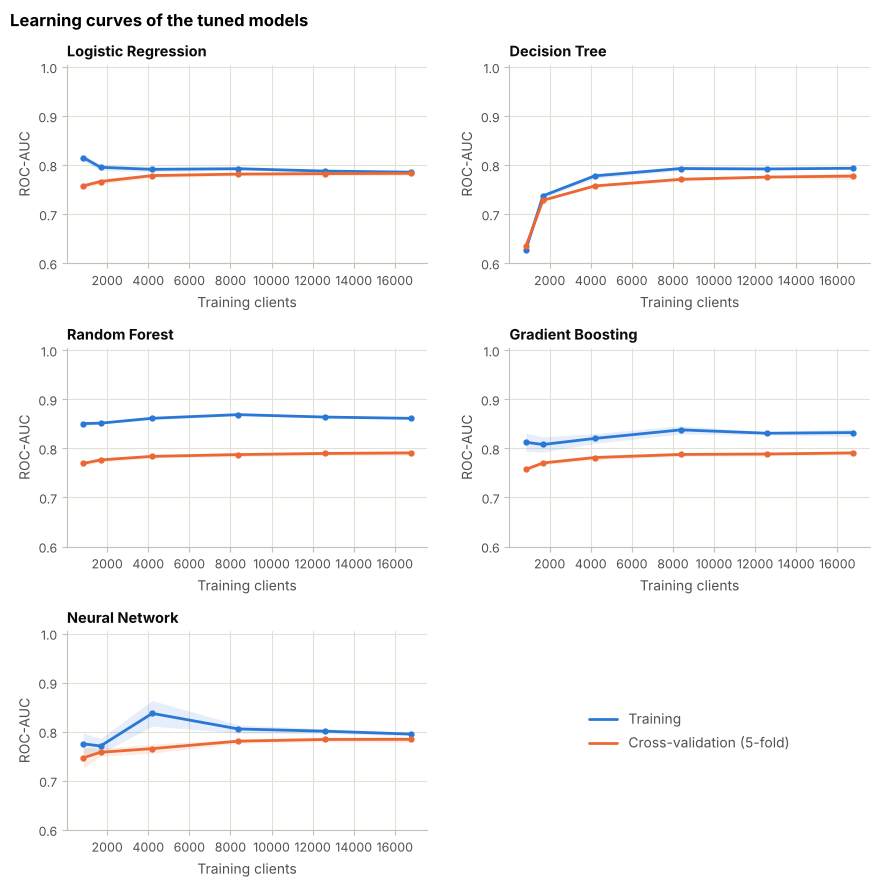

(97s)


,training clients,train ROC-AUC,CV ROC-AUC,gap
model,,,,
Logistic Regression,16780,0.7857,0.7833,0.0024
Decision Tree,16780,0.7937,0.7777,0.0160
Random Forest,16780,0.8614,0.7909,0.0705
Gradient Boosting,16780,0.8324,0.7909,0.0415
Neural Network,16780,0.7952,0.7844,0.0108


In [35]:
fig, axes = plt.subplots(3, 2, figsize=(9, 9.0))
lc_rows, t0 = [], time.time()
for ax, name in zip(axes.flat, MODEL_ORDER):
    sizes, tr, va = learning_curve(searches[name].best_estimator_, X_train, y_train,
                                   train_sizes=[0.05, 0.1, 0.25, 0.5, 0.75, 1.0], cv=CV, scoring='roc_auc', n_jobs=-1)
    for scores, color in [(tr, C_TRAIN), (va, C_VAL)]:
        m, s = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(sizes, m, color=color, marker='o', markersize=3.5)
        ax.fill_between(sizes, m - s, m + s, color=color, alpha=0.12, linewidth=0)
    for n, a, b in zip(sizes, tr.mean(axis=1), va.mean(axis=1)):
        lc_rows.append({'model': name, 'training clients': int(n), 'train ROC-AUC': a, 'CV ROC-AUC': b})
    ax.set_title(name)
    ax.set_xlabel('Training clients')
    ax.set_ylabel('ROC-AUC')
    ax.set_ylim(0.6, 1.005)
axes.flat[5].axis('off')
axes.flat[5].legend(handles=[Line2D([0], [0], color=C_TRAIN, lw=2, label='Training'),
                             Line2D([0], [0], color=C_VAL, lw=2, label='Cross-validation (5-fold)')], loc='center', fontsize=10)
fig.suptitle('Learning curves of the tuned models', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig09_learning_curves')
plt.show()
learning = pd.DataFrame(lc_rows)
learning.to_csv('results/learning_curves.csv', index=False)
print(f'({time.time() - t0:.0f}s)')
learning.groupby('model').last().assign(gap=lambda d: d['train ROC-AUC'] - d['CV ROC-AUC']).loc[MODEL_ORDER].round(4)

With the full training folds (16,780 clients):
* Logistic Regression (gap 0.002) and the NN (0.011) generalise almost perfectly.
* The tree ensembles keep a larger gap (RF 0.071, GB 0.041), which is typical for flexible models, yet they still have the **highest CV scores** (0.791).
* All CV curves are nearly flat over the last 8,000 clients, so more data would bring only small gains.

### 4.4 Neural network: training with validation monitoring
The network is trained one epoch at a time with `partial_fit` (one pass over the training data in mini-batches of 256). After every epoch, the **binary cross-entropy loss, accuracy and ROC-AUC are measured on the training and validation sets**.

**Early stopping:** if the validation loss has not improved by 10⁻⁴ for 20 epochs, training stops and the best epoch's weights are restored. The validation set never updates the weights.

In [36]:
def train_nn_with_monitoring(params, X_tr, y_tr, X_va, y_va, max_epochs=300, patience=20, min_delta=1e-4,
                             seed=RANDOM_STATE):
    """Trains an MLP one epoch at a time (partial_fit = one pass over the training data in mini-batches),
    records loss, accuracy and ROC-AUC on the training and validation sets after every epoch and applies
    early stopping on the validation loss, restoring the weights of the best epoch (patience=None: no stopping)."""
    mlp = MLPClassifier(solver='adam', random_state=seed, **params)
    y_tr, y_va = np.asarray(y_tr), np.asarray(y_va)
    history, best, wait = [], {'loss': np.inf, 'epoch': 0, 'model': None}, 0
    for epoch in range(1, max_epochs + 1):
        mlp.partial_fit(X_tr, y_tr, classes=np.array([0, 1]))
        p_tr, p_va = mlp.predict_proba(X_tr)[:, 1], mlp.predict_proba(X_va)[:, 1]
        history.append({'epoch': epoch,
                        'train_loss': log_loss(y_tr, p_tr, labels=[0, 1]), 'val_loss': log_loss(y_va, p_va, labels=[0, 1]),
                        'train_acc': accuracy_score(y_tr, p_tr >= 0.5), 'val_acc': accuracy_score(y_va, p_va >= 0.5),
                        'train_auc': roc_auc_score(y_tr, p_tr), 'val_auc': roc_auc_score(y_va, p_va)})
        if history[-1]['val_loss'] < best['loss'] - min_delta:
            best, wait = {'loss': history[-1]['val_loss'], 'epoch': epoch, 'model': copy.deepcopy(mlp)}, 0
        else:
            wait += 1
            if patience is not None and wait >= patience:
                break
    return best['model'], pd.DataFrame(history), best['epoch']

# NN inputs: the same preprocessing as in the pipeline, fitted on the training set only
nn_prep = make_preprocessor('signed-log', FEATURES).fit(X_train)
Xtr_nn, Xva_nn = nn_prep.transform(X_train), nn_prep.transform(X_val)
tuned_nn = searches['Neural Network'].best_estimator_.named_steps['clf']
NN_PARAMS = {k: tuned_nn.get_params()[k] for k in ['hidden_layer_sizes', 'activation', 'alpha', 'learning_rate_init', 'batch_size']}
print('Final NN hyperparameters:', NN_PARAMS)

Final NN hyperparameters: {'hidden_layer_sizes': (128, 64, 32), 'activation': 'relu', 'alpha': 1.0, 'learning_rate_init': 0.001, 'batch_size': 256}


Trainable parameters: 15,233 | epochs run: 48 | best epoch (restored): 28 | training time: 10.1s
At the best epoch: loss 0.4169 (train) vs 0.4305 (val); accuracy 0.8243 vs 0.8180; ROC-AUC 0.7990 vs 0.7818


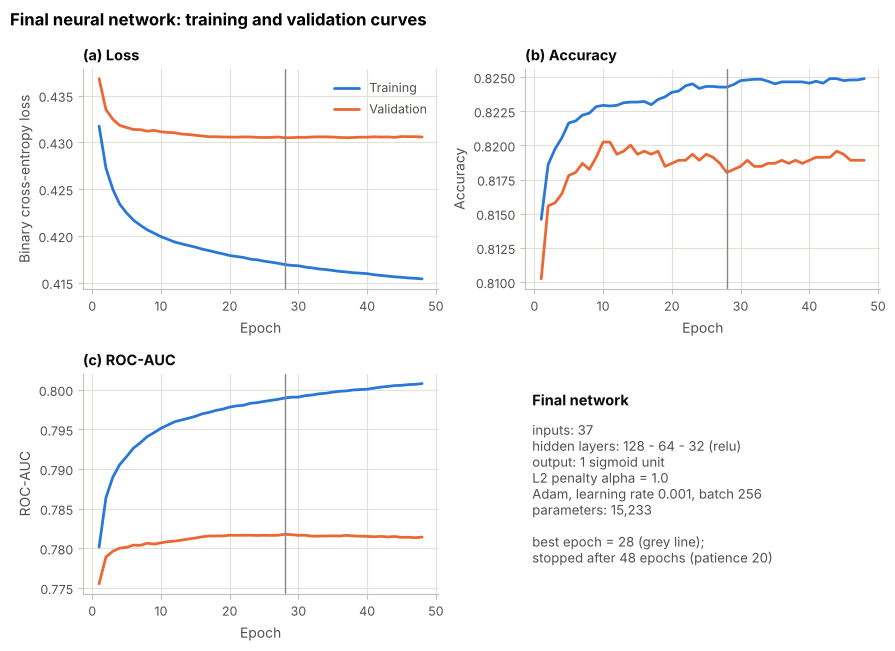

In [37]:
t0 = time.time()
nn_model, nn_history, nn_best_epoch = train_nn_with_monitoring(NN_PARAMS, Xtr_nn, y_train, Xva_nn, y_val)
nn_train_time = time.time() - t0
final_nn = Pipeline([('prep', nn_prep), ('clf', nn_model)])     # fitted preprocessing + best-epoch network
nn_history.to_csv('results/nn_history_final.csv', index=False)
n_weights = sum(w.size for w in nn_model.coefs_) + sum(b.size for b in nn_model.intercepts_)
b = nn_history.loc[nn_history['epoch'] == nn_best_epoch].iloc[0]
print(f'Trainable parameters: {n_weights:,} | epochs run: {len(nn_history)} | best epoch (restored): {nn_best_epoch} '
      f'| training time: {nn_train_time:.1f}s')
print(f"At the best epoch: loss {b['train_loss']:.4f} (train) vs {b['val_loss']:.4f} (val); "
      f"accuracy {b['train_acc']:.4f} vs {b['val_acc']:.4f}; ROC-AUC {b['train_auc']:.4f} vs {b['val_auc']:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(9, 6.6))
panels = [('loss', 'Binary cross-entropy loss', '(a) Loss'), ('acc', 'Accuracy', '(b) Accuracy'),
          ('auc', 'ROC-AUC', '(c) ROC-AUC')]
for ax, (metric, ylab, title) in zip(axes.flat, panels):
    ax.plot(nn_history['epoch'], nn_history[f'train_{metric}'], color=C_TRAIN, label='Training')
    ax.plot(nn_history['epoch'], nn_history[f'val_{metric}'], color=C_VAL, label='Validation')
    ax.axvline(nn_best_epoch, color=MUTED, linewidth=1)
    ax.set_xlabel('Epoch'); ax.set_ylabel(ylab); ax.set_title(title)
axes[0, 0].legend(loc='upper right')
ax = axes[1, 1]
ax.axis('off')
hl = NN_PARAMS['hidden_layer_sizes']
ax.text(0.02, 0.92, 'Final network', fontsize=10.5, fontweight='bold', color=INK, transform=ax.transAxes, va='top')
ax.text(0.02, 0.78, f"inputs: {Xtr_nn.shape[1]}\nhidden layers: {' - '.join(map(str, hl))} ({NN_PARAMS['activation']})\n"
        f"output: 1 sigmoid unit\nL2 penalty alpha = {NN_PARAMS['alpha']}\nAdam, learning rate {NN_PARAMS['learning_rate_init']}, "
        f"batch {NN_PARAMS['batch_size']}\nparameters: {n_weights:,}\n\nbest epoch = {nn_best_epoch} (grey line);\n"
        f"stopped after {len(nn_history)} epochs (patience 20)", fontsize=9.5, color=INK2, transform=ax.transAxes, va='top')
fig.suptitle('Final neural network: training and validation curves', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig10_nn_training_validation_curves')
plt.show()

**Interpretation.**
* Both losses fall quickly in the first ~10 epochs.
* From about epoch 20, the **validation loss stops improving while the training loss keeps falling**. The network begins to learn noise specific to the training data.
* Early stopping caught this: the best epoch was **28** (training loss 0.417, validation loss 0.4305; accuracy 82.4% vs 81.8%; ROC-AUC 0.799 vs 0.782). Training ended at epoch 48, and the epoch-28 weights were restored.
* The remaining gap is small (0.014 in loss). The result is a **good fit**: no under-fitting (the accuracy and AUC are as good as the best tuned models in cross-validation) and over-fitting stopped in time.

### 4.5 Diagnosing under- and over-fitting in the network

(93s)


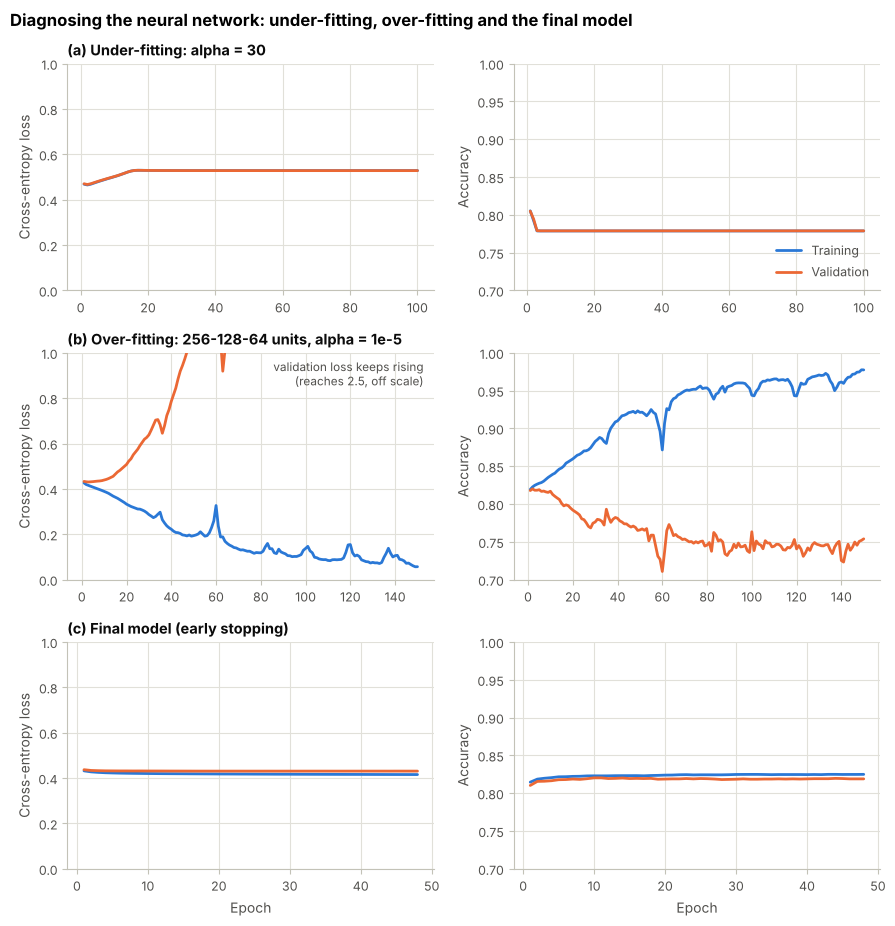

,epochs run,best epoch,val loss (best epoch),final train loss,final val loss,final train acc,final val acc,final train ROC-AUC,final val ROC-AUC
scenario,,,,,,,,,
Under-fitting,100,2,0.4672,0.5285,0.5283,0.7787,0.7789,0.3401,0.3373
Over-fitting,150,3,0.4304,0.0570,2.4737,0.9774,0.7539,0.9970,0.6639
Final model,48,28,0.4305,0.4154,0.4306,0.8249,0.8189,0.8008,0.7814


In [38]:
scenarios = {
    'Under-fitting: alpha = 30 (too much regularisation)': (dict(NN_PARAMS, alpha=30.0), 100, None),
    'Over-fitting: 256-128-64 units, alpha = 1e-5, no early stopping': (dict(NN_PARAMS, hidden_layer_sizes=(256, 128, 64), alpha=1e-5), 150, None),
    f'Final model: tuned, early stopping at epoch {nn_best_epoch}': None,
}
scenario_hist, scenario_rows, t0 = {}, [], time.time()
for title, spec in scenarios.items():
    if spec is None:
        hist, best_ep = nn_history, nn_best_epoch
    else:
        params, epochs, patience = spec
        _, hist, best_ep = train_nn_with_monitoring(params, Xtr_nn, y_train, Xva_nn, y_val, max_epochs=epochs, patience=patience)
    scenario_hist[title] = (hist, best_ep)
    last, best = hist.iloc[-1], hist.iloc[best_ep - 1]
    scenario_rows.append({'scenario': title.split(':')[0], 'epochs run': len(hist), 'best epoch': best_ep,
                          'val loss (best epoch)': best['val_loss'], 'final train loss': last['train_loss'],
                          'final val loss': last['val_loss'], 'final train acc': last['train_acc'],
                          'final val acc': last['val_acc'], 'final train ROC-AUC': last['train_auc'],
                          'final val ROC-AUC': last['val_auc']})
print(f'({time.time() - t0:.0f}s)')

SHORT_TITLES = ['Under-fitting: alpha = 30', 'Over-fitting: 256-128-64 units, alpha = 1e-5', 'Final model (early stopping)']
fig, axes = plt.subplots(3, 2, figsize=(9, 9.4))
for i, (title, (hist, best_ep)) in enumerate(scenario_hist.items()):
    for j, (metric, ylab) in enumerate([('loss', 'Cross-entropy loss'), ('acc', 'Accuracy')]):
        ax = axes[i, j]
        ax.plot(hist['epoch'], hist[f'train_{metric}'], color=C_TRAIN, label='Training')
        ax.plot(hist['epoch'], hist[f'val_{metric}'], color=C_VAL, label='Validation')
        if metric == 'loss':
            ax.set_ylim(0, 1.0)
        else:
            ax.set_ylim(0.7, 1.0)
        ax.set_ylabel(ylab)
        if i == 2:
            ax.set_xlabel('Epoch')
    axes[i, 0].set_title(f'({"abc"[i]}) {SHORT_TITLES[i]}', loc='left')
over_final = scenario_hist[list(scenario_hist)[1]][0]['val_loss'].iloc[-1]
if over_final > 1.0:
    axes[1, 0].text(axes[1, 0].get_xlim()[1] * 0.97, 0.97, f'validation loss keeps rising\n(reaches {over_final:.1f}, off scale)',
                    ha='right', va='top', fontsize=8.5, color=INK2)
axes[0, 1].legend(loc='lower right')
fig.suptitle('Diagnosing the neural network: under-fitting, over-fitting and the final model', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig11_nn_fit_diagnosis')
plt.show()
nn_scenarios = pd.DataFrame(scenario_rows).set_index('scenario')
nn_scenarios.to_csv('results/nn_scenarios.csv')
nn_scenarios.round(4)

* **(a) Under-fitting (alpha = 30).**
  * The L2 penalty forces all weights towards zero. Both losses rise to about 0.529 — the loss of always predicting the base rate — and both accuracies fall to 77.9%, the share of non-defaulters.
  * The network predicts "no default" for everybody: **high bias**.
  * *Fix:* a weaker penalty; CV selected alpha = 1.
* **(b) Over-fitting (256-128-64 neurons, alpha = 10⁻⁵, no early stopping).**
  * The validation loss is lowest at **epoch 3** (0.430). It then **rises steadily to 2.47** by epoch 150, while the training loss falls to 0.057 and the training accuracy reaches 97.7%.
  * Validation accuracy drops to 75.4% and validation ROC-AUC to 0.664.
  * The network memorises the training clients: **high variance**.
  * *Fixes used in the final model:* (1) L2 penalty alpha = 1; (2) an architecture chosen by CV; (3) early stopping with best-weight restoration.
* **(c) Final model:** training and validation curves stay close (4.4).

In [39]:
# Robustness check (training + validation sets only): the final architecture with 10 random initialisations
seed_rows, t0 = [], time.time()
for seed in range(10):
    m, h, be = train_nn_with_monitoring(NN_PARAMS, Xtr_nn, y_train, Xva_nn, y_val, seed=seed)
    p = m.predict_proba(Xva_nn)[:, 1]
    seed_rows.append({'seed': seed, 'best epoch': be, 'val loss': log_loss(y_val, p),
                      'val ROC-AUC': roc_auc_score(y_val, p), 'val PR-AUC': average_precision_score(y_val, p)})
nn_seeds = pd.DataFrame(seed_rows)
nn_seeds.to_csv('results/nn_seed_robustness.csv', index=False)
print(f'({time.time() - t0:.0f}s)')
nn_seeds.drop(columns='seed').describe().loc[['mean', 'std', 'min', 'max']].round(4)

(126s)


,best epoch,val loss,val ROC-AUC,val PR-AUC
mean,39.7000,0.4316,0.7806,0.5442
std,37.6181,0.0016,0.0024,0.0032
min,9.0000,0.4298,0.7747,0.5402
max,137.0000,0.4347,0.7827,0.5487


**Robustness to random initialisation** (training and validation data only). Over 10 random seeds, validation ROC-AUC is **0.781 ± 0.002** (0.775–0.783) and validation loss 0.432 ± 0.002. The early-stopping epoch varies (9–137), but the result does not: the reported network is not a lucky draw.

### 4.6 Training vs validation performance of the final models

In [40]:
def positive_scores(model, X):
    return model.predict_proba(X)[:, 1]

final_models = {name: searches[name].best_estimator_ for name in MODEL_ORDER if name != 'Neural Network'}
final_models['Neural Network'] = final_nn

reference_models = {
    'Decision Tree (default, unpruned)': make_pipeline('Decision Tree', DecisionTreeClassifier(random_state=RANDOM_STATE)).fit(X_train, y_train),
    'Neural Network (default, no early stopping)': make_pipeline('Neural Network', MLPClassifier(random_state=RANDOM_STATE, max_iter=200)).fit(X_train, y_train),
}
fit_rows = []
for name, model in list(reference_models.items()) + list(final_models.items()):
    s_tr, s_va = positive_scores(model, X_train), positive_scores(model, X_val)
    fit_rows.append({'Model': name, 'Train ROC-AUC': roc_auc_score(y_train, s_tr), 'Val ROC-AUC': roc_auc_score(y_val, s_va),
                     'Train PR-AUC': average_precision_score(y_train, s_tr), 'Val PR-AUC': average_precision_score(y_val, s_va),
                     'Train log-loss': log_loss(y_train, s_tr), 'Val log-loss': log_loss(y_val, s_va)})
fit_check = pd.DataFrame(fit_rows).set_index('Model')
fit_check['ROC-AUC gap'] = fit_check['Train ROC-AUC'] - fit_check['Val ROC-AUC']
fit_check.to_csv('results/train_vs_validation.csv')
fit_check.round(4)

,Train ROC-AUC,Val ROC-AUC,Train PR-AUC,Val PR-AUC,Train log-loss,Val log-loss,ROC-AUC gap
Model,,,,,,,
"Decision Tree (default, unpruned)",1.0000,0.6114,1.0000,0.2882,0.0006,9.8791,0.3886
"Neural Network (default, no early stopping)",0.8701,0.7531,0.7112,0.4935,0.3549,0.4839,0.1169
Logistic Regression,0.7855,0.7759,0.5395,0.5253,0.5579,0.5640,0.0095
Decision Tree,0.7958,0.7678,0.5544,0.5272,0.5407,0.5556,0.0279
Random Forest,0.8600,0.7791,0.6590,0.5532,0.4741,0.5224,0.0808
Gradient Boosting,0.8233,0.7777,0.6089,0.5517,0.4021,0.4313,0.0455
Neural Network,0.7990,0.7818,0.5673,0.5449,0.4169,0.4305,0.0172


* **Without regularisation, the flexible models over-fit badly.** The default decision tree drops from 1.000 to 0.611 ROC-AUC, and the default NN from 0.870 to 0.753.
* **After tuning**, all validation scores are 0.768–0.782, with small gaps for LR (0.010), the NN (0.017) and the DT (0.028), and moderate ones for GB (0.046) and RF (0.081).
* The NN has the **best validation ROC-AUC** (0.782). This is slightly optimistic, because the same validation set chose its stopping epoch; the test set gives the unbiased comparison.

### 4.7 Choosing the decision threshold (validation set)
A probability threshold of 0.5 is arbitrary for an imbalanced problem. For each model, the threshold that **maximises F1 on the validation set** is chosen and then applied unchanged to the test set.

In [41]:
def best_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return thresholds[i], precision[i], recall[i], f1[i]

val_scores = {name: positive_scores(m, X_val) for name, m in final_models.items()}
thr_rows = []
for name in MODEL_ORDER:
    t, p, r, f = best_f1_threshold(y_val, val_scores[name])
    pred05 = (val_scores[name] >= 0.5).astype(int)
    thr_rows.append({'Model': name, 'Threshold': t, 'Val precision': p, 'Val recall': r, 'Val F1': f,
                     'Val F1 at 0.5': f1_score(y_val, pred05), 'Val recall at 0.5': recall_score(y_val, pred05)})
thresholds = pd.DataFrame(thr_rows).set_index('Model')
THRESHOLD = thresholds['Threshold'].to_dict()
thresholds.to_csv('results/thresholds.csv')
thresholds.round(4)

,Threshold,Val precision,Val recall,Val F1,Val F1 at 0.5,Val recall at 0.5
Model,,,,,,
Logistic Regression,0.6217,0.5445,0.5352,0.5398,0.5208,0.6298
Decision Tree,0.5879,0.5128,0.5634,0.5369,0.5138,0.6640
Random Forest,0.6098,0.5677,0.5231,0.5445,0.5344,0.6056
Gradient Boosting,0.2895,0.5183,0.5694,0.5427,0.4530,0.3421
Neural Network,0.3347,0.5563,0.5322,0.5440,0.4695,0.3642


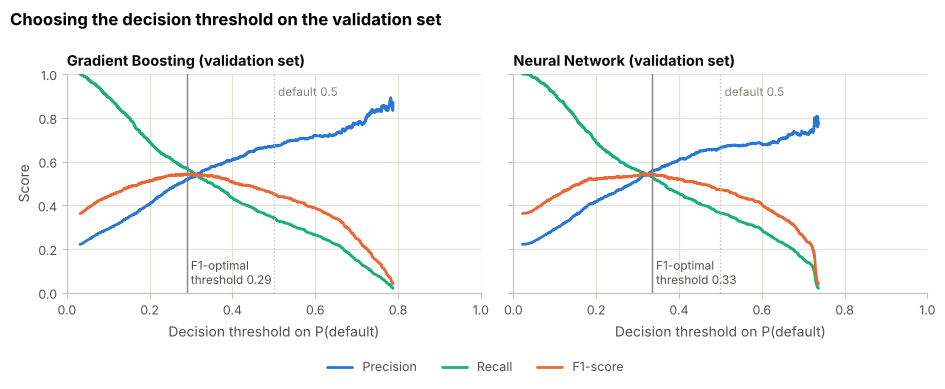

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True)
for ax, name in zip(axes, ['Gradient Boosting', 'Neural Network']):
    precision, recall, thr = precision_recall_curve(y_val, val_scores[name])
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    keep = recall[:-1] >= 0.02          # hide the noisy end where fewer than 2% of defaulters are flagged
    ax.plot(thr[keep], precision[:-1][keep], color='#2a78d6', label='Precision')
    ax.plot(thr[keep], recall[:-1][keep], color='#1baf7a', label='Recall')
    ax.plot(thr[keep], f1[keep], color='#eb6834', label='F1-score')
    ax.axvline(THRESHOLD[name], color=MUTED, linewidth=1)
    ax.axvline(0.5, color=AXIS, linewidth=1, linestyle=':')
    ax.text(THRESHOLD[name] + 0.01, 0.04, f'F1-optimal\nthreshold {THRESHOLD[name]:.2f}', fontsize=8.5, color=INK2)
    ax.text(0.51, 0.90, 'default 0.5', fontsize=8.5, color=MUTED)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.0)
    ax.set_xlabel('Decision threshold on P(default)')
    ax.set_title(f'{name} (validation set)')
axes[0].set_ylabel('Score')
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle('Choosing the decision threshold on the validation set', x=0.01, ha='left')
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_fig(fig, 'fig12_threshold_selection')
plt.show()

**Threshold results.**
* The unweighted models (GB, NN) need a **lower** threshold (0.29 and 0.33). At 0.5 they flag too few defaulters (validation recall 34–36%).
* The class-weighted models (LR, DT, RF) already produce inflated probabilities, so their F1-optimal threshold is **higher** (0.59–0.62).
* Threshold tuning raises the validation F1 of GB from 0.453 to 0.543 and of the NN from 0.470 to 0.544.

---
## Stage 5 — Final Evaluation and Comparison

### 5.1 Choice of evaluation metrics
The positive class is **default**.
* **ROC-AUC** (with the Gini coefficient = 2·AUC − 1, and the **KS** statistic): threshold-free *ranking* quality, the standard in credit scoring. A bank uses scores to rank applicants.
* **PR-AUC** (average precision): focuses on the minority class and is more informative than ROC-AUC when positives are rare.
* **Recall** (share of defaulters caught), **precision** (share of flagged clients who really default) and **F1** (their balance) at the tuned threshold. A missed defaulter (FN) costs the lent money; a false alarm (FP) costs a good customer.
* **Specificity** and **accuracy** for completeness; accuracy alone is misleading (77.9% by predicting "no default").
* **Brier score:** quality of the predicted probabilities (calibration), which matters if the scores are used as default probabilities.
* **Confusion matrices** show the actual numbers of each error type.

### 5.2 Test-set results (used once)

In [43]:
def ks_statistic(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    return float(np.max(tpr - fpr))

def evaluate(model_name, X, y, threshold):
    s = positive_scores(final_models[model_name], X)
    pred = (s >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    auc = roc_auc_score(y, s)
    return {'Threshold': threshold, 'Accuracy': accuracy_score(y, pred), 'Precision': precision_score(y, pred),
            'Recall': recall_score(y, pred), 'Specificity': tn / (tn + fp), 'F1-score': f1_score(y, pred),
            'ROC-AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks_statistic(y, s), 'PR-AUC': average_precision_score(y, s),
            'Brier score': brier_score_loss(y, s), 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn}

test_results = pd.DataFrame({n: evaluate(n, X_test, y_test, THRESHOLD[n]) for n in MODEL_ORDER}).T
test_at_05 = pd.DataFrame({n: evaluate(n, X_test, y_test, 0.5) for n in MODEL_ORDER}).T
for t in (test_results, test_at_05):
    for c in ['TP', 'FN', 'FP', 'TN']:
        t[c] = t[c].astype(int)
test_results.to_csv('results/test_metrics.csv')
test_at_05.to_csv('results/test_metrics_threshold_0_5.csv')
print(f'Test set: {len(y_test):,} clients ({int(y_test.sum())} defaults, {int((y_test == 0).sum())} non-defaults)')
test_results.drop(columns=['TP', 'FN', 'FP', 'TN']).round(4)

Test set: 4,495 clients (995 defaults, 3500 non-defaults)


,Threshold,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,Gini,KS,PR-AUC,Brier score
Logistic Regression,0.6217,0.7929,0.5335,0.5116,0.8729,0.5223,0.7680,0.5360,0.4116,0.5345,0.1859
Decision Tree,0.5879,0.7806,0.5041,0.5558,0.8446,0.5287,0.7634,0.5267,0.4109,0.5337,0.1873
Random Forest,0.6098,0.7980,0.5471,0.5075,0.8806,0.5266,0.7756,0.5513,0.4192,0.5588,0.1723
Gradient Boosting,0.2895,0.7882,0.5199,0.5638,0.8520,0.5410,0.7766,0.5532,0.4183,0.5666,0.1347
Neural Network,0.3347,0.7927,0.5331,0.5095,0.8731,0.5211,0.7717,0.5434,0.4252,0.5500,0.1361


In [44]:
compare_05 = pd.DataFrame({
    'F1 at 0.5': test_at_05['F1-score'], 'F1 at tuned threshold': test_results['F1-score'],
    'Recall at 0.5': test_at_05['Recall'], 'Recall at tuned threshold': test_results['Recall'],
    'Precision at 0.5': test_at_05['Precision'], 'Precision at tuned threshold': test_results['Precision'],
})
compare_05.round(4)

,F1 at 0.5,F1 at tuned threshold,Recall at 0.5,Recall at tuned threshold,Precision at 0.5,Precision at tuned threshold
Logistic Regression,0.5236,0.5223,0.6251,0.5116,0.4504,0.5335
Decision Tree,0.5052,0.5287,0.6533,0.5558,0.4119,0.5041
Random Forest,0.5333,0.5266,0.5950,0.5075,0.4833,0.5471
Gradient Boosting,0.4739,0.5410,0.3608,0.5638,0.6904,0.5199
Neural Network,0.4898,0.5211,0.3879,0.5095,0.6644,0.5331


**Results on the 4,495 test clients (995 defaulters).**
* **Gradient Boosting** is best on all three main metrics: ROC-AUC **0.777**, PR-AUC **0.567** and F1 **0.541** (recall 56.4%, precision 52.0%).
* The Random Forest (0.776 / 0.559 / 0.527) and the Neural Network (0.772 / 0.550 / 0.521) follow, then Logistic Regression (0.768 / 0.535 / 0.522) and the Decision Tree (0.763 / 0.534 / 0.529).
* Test ROC-AUCs are about 0.014 below the CV scores for every model. This is normal sampling variation of one 4,495-client set, and the ranking of the models is unchanged.

**Threshold matters.** At 0.5, gradient boosting has the highest *accuracy* (82.3%) but catches only **36%** of defaulters. The validation-tuned threshold raises its recall to **56%** and F1 from 0.474 to 0.541; for the NN, F1 rises from 0.490 to 0.521. For the class-weighted LR and RF, 0.5 was already near-optimal (test F1 changes by less than 0.01); for the decision tree the tuned threshold adds +0.023.

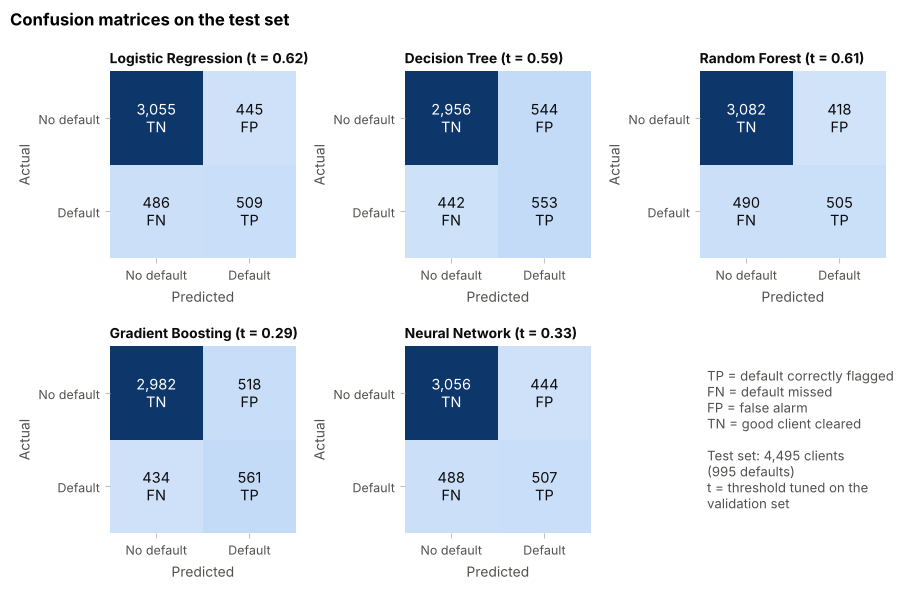

In [45]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6.0))
for ax, name in zip(axes.flat, MODEL_ORDER):
    r = test_results.loc[name]
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]]).astype(int)
    ax.imshow(cm, cmap=BLUES, vmin=0, vmax=cm.max())
    for (i, j), v in np.ndenumerate(cm):
        tag = [['TN', 'FP'], ['FN', 'TP']][i][j]
        ax.text(j, i, f'{v:,}\n{tag}', ha='center', va='center', fontsize=10.5, color='white' if v > cm.max() * 0.55 else INK)
    ax.set_xticks([0, 1], ['No default', 'Default'])
    ax.set_yticks([0, 1], ['No default', 'Default'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f'{name} (t = {THRESHOLD[name]:.2f})', fontsize=10)
note = axes.flat[5]
note.axis('off')
note.text(0.04, 0.5, 'TP = default correctly flagged\nFN = default missed\nFP = false alarm\nTN = good client cleared\n\n'
          f'Test set: {len(y_test):,} clients\n({int(y_test.sum())} defaults)\nt = threshold tuned on the\nvalidation set',
          va='center', ha='left', fontsize=9.5, color=INK2, transform=note.transAxes)
fig.suptitle('Confusion matrices on the test set', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig13_confusion_matrices')
plt.show()

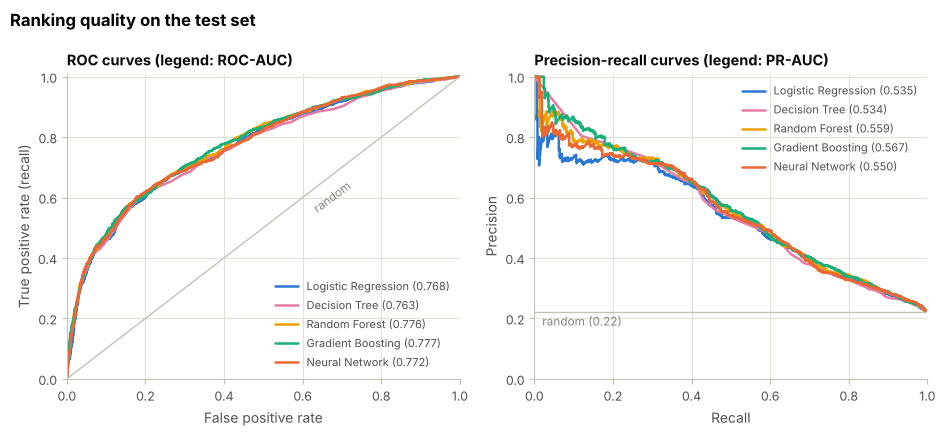

In [46]:
test_scores = {n: positive_scores(final_models[n], X_test) for n in MODEL_ORDER}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.4))
for name in MODEL_ORDER:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], linewidth=1.8, label=f"{name} ({test_results.loc[name, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, test_scores[name])
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], linewidth=1.8, label=f"{name} ({test_results.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color=AXIS, linewidth=1)
axes[0].text(0.62, 0.55, 'random', color=MUTED, fontsize=8.5, rotation=37)
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate (recall)')
axes[0].set_title('ROC curves (legend: ROC-AUC)')
axes[1].axhline(y_test.mean(), color=AXIS, linewidth=1)
axes[1].text(0.02, y_test.mean() - 0.045, f'random ({y_test.mean():.2f})', color=MUTED, fontsize=8.5, ha='left')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-recall curves (legend: PR-AUC)')
for ax in axes:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
    ax.legend(loc='lower right' if ax is axes[0] else 'upper right', fontsize=8)
fig.suptitle('Ranking quality on the test set', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig14_roc_pr_curves')
plt.show()

In [47]:
# 95% confidence intervals from 2,000 paired bootstrap resamples of the test set
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
preds = {n: (test_scores[n] >= THRESHOLD[n]).astype(int) for n in MODEL_ORDER}
REFERENCE = 'Neural Network'   # the mandatory model is compared with each traditional model
B, t0 = 2000, time.time()
boot = {n: {'ROC-AUC': [], 'PR-AUC': [], 'F1-score': []} for n in MODEL_ORDER}
for _ in range(B):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    yb = y_arr[idx]
    for n in MODEL_ORDER:
        boot[n]['ROC-AUC'].append(roc_auc_score(yb, test_scores[n][idx]))
        boot[n]['PR-AUC'].append(average_precision_score(yb, test_scores[n][idx]))
        boot[n]['F1-score'].append(f1_score(yb, preds[n][idx]))
ci_rows, diff_rows = [], []
for n in MODEL_ORDER:
    for metric, vals in boot[n].items():
        vals = np.array(vals)
        lo, hi = np.percentile(vals, [2.5, 97.5])
        ci_rows.append({'Model': n, 'Metric': metric, 'Estimate': test_results.loc[n, metric], 'CI low': lo, 'CI high': hi})
        if n != REFERENCE:
            d = np.array(boot[REFERENCE][metric]) - vals
            dlo, dhi = np.percentile(d, [2.5, 97.5])
            diff_rows.append({'Comparison': f'{REFERENCE} - {n}', 'Metric': metric,
                              'Difference': test_results.loc[REFERENCE, metric] - test_results.loc[n, metric],
                              'CI low': dlo, 'CI high': dhi, 'Share of resamples <= 0': float((d <= 0).mean())})
test_ci = pd.DataFrame(ci_rows); test_ci.to_csv('results/test_bootstrap_ci.csv', index=False)
paired = pd.DataFrame(diff_rows); paired.to_csv('results/paired_differences.csv', index=False)
print(f'Paired differences are computed as {REFERENCE} minus each traditional model   ({time.time() - t0:.0f}s)')
test_ci.assign(**{'95% CI': test_ci.apply(lambda r: f"[{r['CI low']:.3f}, {r['CI high']:.3f}]", axis=1)}) \
    .pivot(index='Model', columns='Metric', values='95% CI').loc[MODEL_ORDER]

Paired differences are computed as Neural Network minus each traditional model   (74s)


Metric,F1-score,PR-AUC,ROC-AUC
Model,,,
Logistic Regression,"[0.495, 0.549]","[0.501, 0.568]","[0.750, 0.785]"
Decision Tree,"[0.503, 0.553]","[0.503, 0.567]","[0.745, 0.781]"
Random Forest,"[0.500, 0.554]","[0.527, 0.592]","[0.758, 0.793]"
Gradient Boosting,"[0.515, 0.566]","[0.535, 0.598]","[0.759, 0.794]"
Neural Network,"[0.494, 0.547]","[0.517, 0.584]","[0.754, 0.789]"


In [48]:
paired.round(4)

,Comparison,Metric,Difference,CI low,CI high,Share of resamples <= 0
0,Neural Network - Logistic Regression,ROC-AUC,0.0037,-0.0011,0.0088,0.0620
1,Neural Network - Logistic Regression,PR-AUC,0.0155,0.0043,0.0263,0.0020
2,Neural Network - Logistic Regression,F1-score,-0.0013,-0.0146,0.0117,0.5825
3,Neural Network - Decision Tree,ROC-AUC,0.0084,0.0007,0.0162,0.0150
4,Neural Network - Decision Tree,PR-AUC,0.0163,0.0021,0.0302,0.0100
5,Neural Network - Decision Tree,F1-score,-0.0076,-0.0219,0.0066,0.8585
6,Neural Network - Random Forest,ROC-AUC,-0.0039,-0.0093,0.0017,0.9355
7,Neural Network - Random Forest,PR-AUC,-0.0087,-0.0234,0.0051,0.8855
8,Neural Network - Random Forest,F1-score,-0.0055,-0.0164,0.0058,0.8355
9,Neural Network - Gradient Boosting,ROC-AUC,-0.0049,-0.0105,0.0005,0.9610


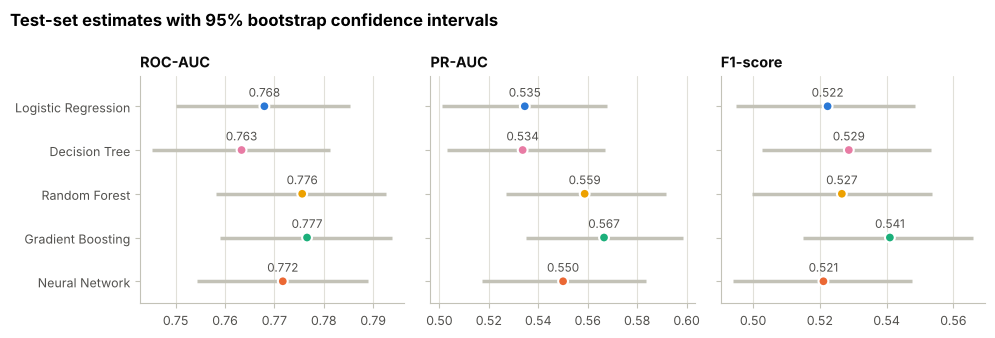

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
ypos = np.arange(len(MODEL_ORDER))[::-1]
for ax, metric in zip(axes, ['ROC-AUC', 'PR-AUC', 'F1-score']):
    sub = test_ci[test_ci['Metric'] == metric].set_index('Model').loc[MODEL_ORDER]
    ax.hlines(ypos, sub['CI low'], sub['CI high'], color=AXIS, linewidth=2.5)
    ax.scatter(sub['Estimate'], ypos, s=50, color=[MODEL_COLORS[n] for n in MODEL_ORDER], edgecolor='white', linewidth=1.5, zorder=3)
    for yy, est in zip(ypos, sub['Estimate']):
        ax.text(est, yy + 0.22, f'{est:.3f}', ha='center', fontsize=8.5, color=INK2)
    ax.set_title(metric)
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(ypos, MODEL_ORDER)
axes[0].set_ylim(-0.5, len(MODEL_ORDER) - 0.3)
fig.suptitle('Test-set estimates with 95% bootstrap confidence intervals', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig15_test_confidence_intervals')
plt.show()

**How certain are these differences?** 2,000 paired bootstrap resamples of the test set were drawn.
* **All five models overlap** in ROC-AUC (intervals about ±0.018).
* **NN vs Gradient Boosting:** GB is better in PR-AUC (difference 0.017, 95% CI 0.003–0.030) and F1 (0.020, CI 0.007–0.033). Those differences are statistically clear; for ROC-AUC GB is better in 96% of resamples.
* **NN vs Logistic Regression and Decision Tree:** the NN is significantly better in PR-AUC (+0.016 each).
* **NN vs Random Forest:** no significant difference on any metric.

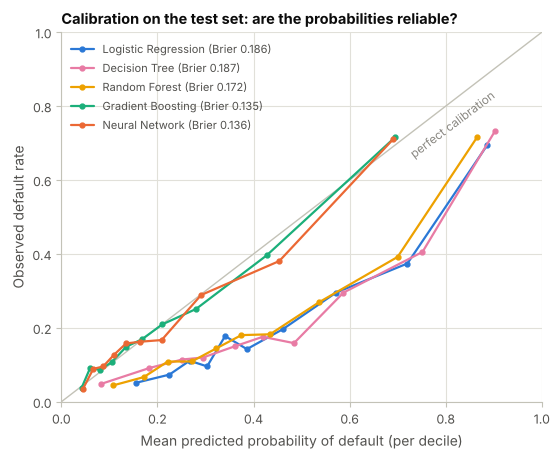

In [50]:
fig, ax = plt.subplots(figsize=(6.2, 4.8))
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
ax.text(0.72, 0.66, 'perfect calibration', color=MUTED, fontsize=8.5, rotation=37)
for name in MODEL_ORDER:
    frac, mean_pred = calibration_curve(y_test, test_scores[name], n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac, color=MODEL_COLORS[name], marker='o', markersize=3.5, linewidth=1.6,
            label=f"{name} (Brier {test_results.loc[name, 'Brier score']:.3f})")
ax.set_xlabel('Mean predicted probability of default (per decile)')
ax.set_ylabel('Observed default rate')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc='upper left', fontsize=8)
ax.set_title('Calibration on the test set: are the probabilities reliable?')
save_fig(fig, 'fig16_calibration')
plt.show()

**Calibration.** GB and the NN produce **well-calibrated probabilities** (Brier 0.135 and 0.136): their predicted default probabilities match the observed default rates. The class-weighted models (LR, DT, RF; Brier 0.172–0.187) systematically **over-estimate** the risk. This is the side effect of re-weighting the classes. It does not hurt ranking or thresholded decisions, but it matters if the scores are used as probabilities (e.g. for pricing or loss provisions).

(9s)


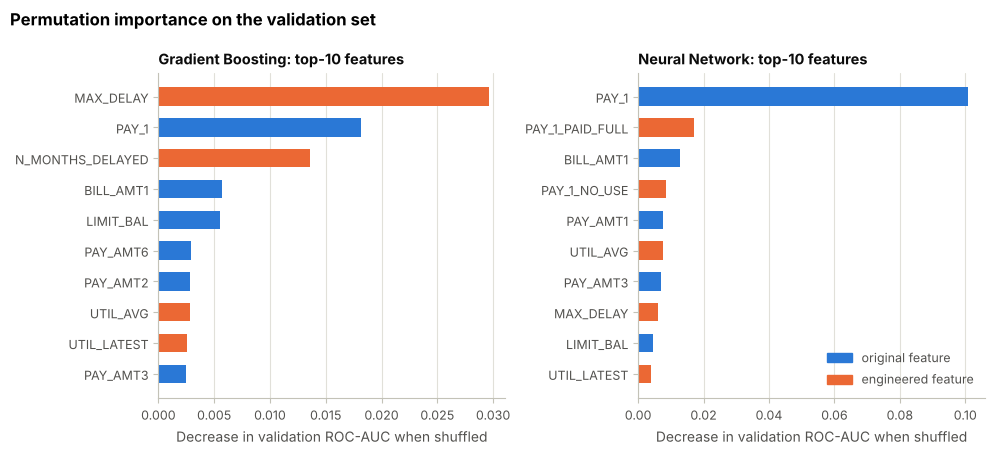

,Gradient Boosting,Neural Network
MAX_DELAY,0.0296,0.0062
PAY_1,0.0181,0.1010
N_MONTHS_DELAYED,0.0136,0.0009
BILL_AMT1,0.0057,0.0129
LIMIT_BAL,0.0056,0.0045
PAY_AMT6,0.0029,0.0007
PAY_AMT2,0.0028,0.0035
UTIL_AVG,0.0028,0.0076
UTIL_LATEST,0.0026,0.0040
PAY_AMT3,0.0025,0.0069


In [51]:
t0 = time.time()
perm = {}
for name in ['Gradient Boosting', 'Neural Network']:
    r = permutation_importance(final_models[name], X_val, y_val, scoring='roc_auc', n_repeats=5,
                               random_state=RANDOM_STATE, n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=X_val.columns).sort_values(ascending=False)
importance = pd.DataFrame(perm).sort_values('Gradient Boosting', ascending=False)
importance.to_csv('results/permutation_importance.csv')
print(f'({time.time() - t0:.0f}s)')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, name in zip(axes, perm):
    top = perm[name].head(10)[::-1]
    ax.barh(top.index, top.values, color=[C_YES if c in ENGINEERED + PAY1_STATUS else C_NO for c in top.index], height=0.6)
    ax.set_title(f'{name}: top-10 features')
    ax.set_xlabel('Decrease in validation ROC-AUC when shuffled')
    ax.grid(axis='y', visible=False)
axes[1].legend(handles=[Patch(color=C_NO, label='original feature'), Patch(color=C_YES, label='engineered feature')],
               loc='lower right')
fig.suptitle('Permutation importance on the validation set', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig17_permutation_importance')
plt.show()
importance.head(10).round(4)

**What drives the predictions (permutation importance on the validation set).**
* **Gradient Boosting** relies most on the engineered `MAX_DELAY` (ROC-AUC drop 0.030), then `PAY_1` (0.018) and `N_MONTHS_DELAYED` (0.014).
* **The NN** relies mainly on `PAY_1` (0.101) and the `PAY_1` status indicators.
* Both then use the latest bill, the limit, utilisation and recent payment amounts.
* Personal attributes play almost no role.

This agrees with the relevance analysis in Stage 1: **recent repayment behaviour is what predicts default**.

### 5.3 Final model comparison

In [52]:
comparison = pd.DataFrame({
    'CV ROC-AUC': tuning_summary.loc[MODEL_ORDER, 'CV ROC-AUC'],
    'Val ROC-AUC': fit_check.loc[MODEL_ORDER, 'Val ROC-AUC'],
    'Threshold': pd.Series(THRESHOLD)[MODEL_ORDER],
    'Test Accuracy': test_results.loc[MODEL_ORDER, 'Accuracy'],
    'Test Precision': test_results.loc[MODEL_ORDER, 'Precision'],
    'Test Recall': test_results.loc[MODEL_ORDER, 'Recall'],
    'Test F1': test_results.loc[MODEL_ORDER, 'F1-score'],
    'Test ROC-AUC': test_results.loc[MODEL_ORDER, 'ROC-AUC'],
    'Test PR-AUC': test_results.loc[MODEL_ORDER, 'PR-AUC'],
    'Test KS': test_results.loc[MODEL_ORDER, 'KS'],
    'Brier': test_results.loc[MODEL_ORDER, 'Brier score'],
    'Tuning time (s)': tuning_summary.loc[MODEL_ORDER, 'Tuning time (s)'],
})
comparison.to_csv('results/final_comparison.csv')
comparison.round(4)

,CV ROC-AUC,Val ROC-AUC,Threshold,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC,Test KS,Brier,Tuning time (s)
Logistic Regression,0.7833,0.7759,0.6217,0.7929,0.5335,0.5116,0.5223,0.7680,0.5345,0.4116,0.1859,45.7266
Decision Tree,0.7777,0.7678,0.5879,0.7806,0.5041,0.5558,0.5287,0.7634,0.5337,0.4109,0.1873,40.3256
Random Forest,0.7909,0.7791,0.6098,0.7980,0.5471,0.5075,0.5266,0.7756,0.5588,0.4192,0.1723,278.4878
Gradient Boosting,0.7909,0.7777,0.2895,0.7882,0.5199,0.5638,0.5410,0.7766,0.5666,0.4183,0.1347,123.5262
Neural Network,0.7844,0.7818,0.3347,0.7927,0.5331,0.5095,0.5211,0.7717,0.5500,0.4252,0.1361,208.9276


**Which model is most suitable?**

| Rank | Model | Evidence |
|---|---|---|
| 1 | **Gradient Boosting** | Joint-best CV ROC-AUC (0.791). Best test ROC-AUC (0.777), PR-AUC (0.567) and F1 (0.541; significantly better than the NN). Best-calibrated probabilities (Brier 0.135). Fast to train. |
| 2 | Random Forest | Joint-best CV ROC-AUC (0.791) and close on the test set (0.776), but its class-weighted probabilities are poorly calibrated (Brier 0.172) and it is the slowest model to tune. |
| 3 | Neural Network | Best *validation* ROC-AUC (0.782), highest KS (0.425) and well calibrated. Significantly behind GB in PR-AUC and F1 on the test set; needed the most careful regularisation; least interpretable. |
| 4 | Logistic Regression | Simple, transparent and stable (no over-fitting), but limited by its linear form (test ROC-AUC 0.768). |
| 5 | Decision Tree | Readable rules, but the weakest ranking (test ROC-AUC 0.763). |

**Recommendation: Gradient Boosting** (`HistGradientBoostingClassifier`, 31 leaves, learning rate 0.03, 194 rounds, threshold 0.29). It catches **56% of defaulters with 52% precision** on unseen clients and gives reliable default probabilities.

---
## 6. Discussion and conclusion

**Neural network vs traditional models.**
* The MLP was competitive: 3rd of 5 on the test set, best on the validation set, and well calibrated. It was significantly better than logistic regression and the single decision tree in PR-AUC.
* It did **not** beat the tree ensembles, in line with research showing that gradient-boosted trees remain hard to beat on medium-sized tabular data. Trees split directly on thresholds such as "delayed ≥ 2 months", while a network has to approximate such steps with smooth functions.
* The NN also needed the most care:
  * 35 candidate architectures;
  * an L2 penalty (alpha = 1) and early stopping;
  * monitoring of training curves.
  Without these it either memorised the training data (validation loss up to 2.47) or collapsed to predicting "no default".
* Its decisions are hard to explain, which matters in lending, where customers can ask why they were refused.

**Main findings.**
1. **Repayment history is the key information.** The most recent status, the number of delayed months and the longest delay dominate every model. The engineered features improved all models in cross-validation.
2. Data preparation had to deal with undocumented codes, duplicates and very heavy-tailed amounts. **Keeping the outliers and transforming the amounts** worked better than deleting clients.
3. Regularisation made the flexible models generalise: large leaves (trees), averaging (RF), small learning rate + early stopping (GB), and L2 + early stopping (NN).
4. For an imbalanced target, **tuning the decision threshold on validation data** is essential. It raised the recall of the best model from 36% to 56%.
5. **Gradient boosting is the most suitable model** for this dataset.

**Limitations and future improvements.**
* The data are from one bank in 2005 and only six months of history, so performance on today's clients is unknown.
* The threshold maximises F1. A real lender would use its actual costs, where a missed default is usually far more expensive than a false alarm.
* Sex, age and marital status may be legally protected attributes. Removing them costs almost nothing (−0.0002 ROC-AUC for GB), so a deployed model should drop them and be checked for fairness.
* Possible improvements:
  * cost-sensitive threshold selection;
  * probability calibration of the class-weighted models;
  * SHAP explanations for individual decisions;
  * a stacked ensemble of GB and the NN;
  * LightGBM/XGBoost with Bayesian hyperparameter search;
  * retraining the final model on training + validation data.

In [53]:
summary = {
    'n_raw': int(len(raw)), 'n_clean': int(len(data)), 'n_duplicates_removed': int(dup_exact.sum()),
    'n_feature_duplicates': int(dup_features.sum()), 'n_conflicting_groups': int(conflicting),
    'dup_inactive_share': float(inactive), 'n_edu_recoded': int(edu_fix.sum()), 'n_mar_recoded': int(mar_fix.sum()),
    'n_features': len(FEATURES), 'n_inputs': int(n_inputs),
    'outlier_values': int(is_outlier.values.sum()), 'outlier_clients': int(outlier_rows.sum()),
    'outlier_default_rate': float(data.loc[outlier_rows, 'DEFAULT'].mean()),
    'skew_median_raw': float(skew_table['skewness (raw)'].abs().median()),
    'skew_median_log': float(skew_table['skewness (signed log)'].abs().median()),
    'vif_over_10': int((vif > 10).sum()), 'vif_median': float(vif.median()), 'vif_max': float(vif.max()),
    'clipped': clipped, 'nn_params': {k: (list(v) if isinstance(v, tuple) else v) for k, v in NN_PARAMS.items()},
    'nn_trainable_parameters': int(n_weights), 'nn_best_epoch': int(nn_best_epoch),
    'nn_epochs_run': int(len(nn_history)), 'nn_train_time_s': round(nn_train_time, 2),
    'gb_rounds': int(gb_rounds_used[0]), 'reference_model': REFERENCE,
    'versions': {'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                 'scipy': scipy.__version__, 'matplotlib': mpl.__version__, 'seaborn': sns.__version__},
}
with open('results/summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)
print('Saved results/summary.json,', len(os.listdir('results')), 'result files and', len(os.listdir('figures')), 'figures')

Saved results/summary.json, 21 result files and 17 figures
